# **IMPORT DATA**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# **DATA UNDERSTANDING**

In [ ]:
user = pd.read_excel('user.xlsx')
activity = pd.read_excel('activity.xlsx')
transactions = pd.read_excel('transactions.xlsx')
status = pd.read_excel('status.xlsx')

- user: Siapa customer dan melalui channel apa mereka diperoleh
- activity: Bagaimana customer menggunakan platform
- transactions: Bagaimana customer bertransaksi dan nilai ekonominya
- status: Apakah customer active/churn dan bagaimana riwayat borrowing-nya

## **User**

In [ ]:
user

,user_id,signup_date,acquisition_channel,age,city
0,1,2024-01-01,Referral,33.0,Jakarta
1,2,2024-01-02,Affiliate,23.0,Bandung
2,3,2024-01-03,Organic,26.0,Jakarta
3,4,2024-01-04,Referral,28.0,Bandung
4,5,2024-01-05,Referral,47.0,Bandung
...,...,...,...,...,...
245,246,2024-09-02,Ads,33.0,Jakarta
246,247,2024-09-03,Organic,32.0,Jakarta
247,248,2024-09-04,Organic,51.0,Jakarta
248,249,2024-09-05,Organic,22.0,Bandung


- user_id:	ID unik yang mengidentifikasi setiap customer
- signup_date:	Tanggal customer melakukan registrasi (1 Januari 2024 - 6 September 2024)
- acquisition_channel:	Channel yang menjadi sumber customer diperoleh
- age:	Usia customer
- city:	Kota tempat customer berada

In [ ]:
user.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   user_id              250 non-null    int64         
 1   signup_date          250 non-null    datetime64[ns]
 2   acquisition_channel  250 non-null    object        
 3   age                  240 non-null    float64       
 4   city                 250 non-null    object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(2)
memory usage: 9.9+ KB


Terdapat missing value pada kolom age

## **Activity**

In [ ]:
activity

,user_id,event_date,session_count,feature_used
0,1,2025-03-26,1,payment
1,1,2025-01-01,3,loan_apply
2,1,2025-03-18,4,payment
3,1,2025-03-06,1,promo_click
4,1,2025-02-01,2,promo_click
...,...,...,...,...
2954,250,2025-04-07,3,loan_apply
2955,250,2025-03-22,3,browse
2956,250,2025-04-08,3,promo_click
2957,250,2025-04-10,4,loan_apply


- user_id:	ID customer yang melakukan aktivitas
- event_date:	Tanggal ketika customer melakukan aktivitas (1 Januari 2025 - 30 April 2025)
- session_count:	Jumlah sesi yang dilakukan customer pada aktivitas tersebut
- feature_used:	Fitur yang digunakan customer

In [ ]:
activity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2959 entries, 0 to 2958
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   user_id        2959 non-null   int64         
 1   event_date     2959 non-null   datetime64[ns]
 2   session_count  2959 non-null   int64         
 3   feature_used   2959 non-null   object        
dtypes: datetime64[ns](1), int64(2), object(1)
memory usage: 92.6+ KB


## **Status**

In [ ]:
status

,user_id,loan_count,avg_transaction_amount,days_since_last_activity,is_churn,churn_date
0,1,7,4.252810e+06,51,0,NaN
1,2,6,3.331625e+06,39,0,NaN
2,3,6,3.574123e+06,33,0,NaN
3,4,2,2.630618e+06,33,0,NaN
4,5,5,4.629785e+06,29,0,NaN
...,...,...,...,...,...,...
245,246,2,3.301796e+06,10,0,NaN
246,247,1,1.134780e+06,89,1,1.737763e+18
247,248,7,2.721008e+06,77,0,NaN
248,249,1,3.201004e+06,16,0,NaN


- user_id:	ID unik customer
- loan_count:	Jumlah loan/peminjaman yang dilakukan customer
- avg_transaction_amount:	Rata-rata nilai transaksi customer
- days_since_last_activity:	Jumlah hari sejak aktivitas terakhir customer
- is_churn:	Indikator status churn: 1 = churn, 0 = active
- churn_date:	Tanggal customer dikategorikan churn

In [ ]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)

In [ ]:
status['avg_transaction_amount'].head()

,avg_transaction_amount
0,4252809.86
1,3331624.67
2,3574122.67
3,2630617.50
4,4629784.80


In [ ]:
status.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 6 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   250 non-null    int64  
 1   loan_count                250 non-null    int64  
 2   avg_transaction_amount    250 non-null    float64
 3   days_since_last_activity  250 non-null    int64  
 4   is_churn                  250 non-null    int64  
 5   churn_date                74 non-null     float64
dtypes: float64(2), int64(4)
memory usage: 11.8 KB


## **Transaction**

In [ ]:
transactions

,user_id,transaction_date,amount
0,1,2025-01-30,4967920
1,1,2025-03-22,4660351
2,1,2025-02-01,4813094
3,1,2025-04-20,3395453
4,1,2025-03-11,5970747
...,...,...,...
1009,248,2025-02-26,849045
1010,248,2025-01-14,5411634
1011,248,2025-02-13,972109
1012,249,2025-04-12,3201004


- user_id:	ID customer yang melakukan transaksi
- transaction_date:	Tanggal transaksi dilakukan (1 Januari 2025 - 30 April 2025)
- amount:	Nilai uang dari setiap transaksi

In [ ]:
transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           1014 non-null   int64         
 1   transaction_date  1014 non-null   datetime64[ns]
 2   amount            1014 non-null   int64         
dtypes: datetime64[ns](1), int64(2)
memory usage: 23.9 KB


# **DATA PREPROCESSING**

## **Parsing Date**

In [ ]:
user["signup_date"] = pd.to_datetime(
    user["signup_date"],
    errors="coerce"
)

activity["event_date"] = pd.to_datetime(
    activity["event_date"],
    errors="coerce"
)

transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"],
    errors="coerce"
)

status["churn_date"] = pd.to_datetime(
    status["churn_date"],
    errors="coerce"
)

In [ ]:
print(user.isna().sum())
print(activity.isna().sum())
print(transactions.isna().sum())
print(status.isna().sum())

user_id                 0
signup_date             0
acquisition_channel     0
age                    10
city                    0
dtype: int64
user_id          0
event_date       0
session_count    0
feature_used     0
dtype: int64
user_id             0
transaction_date    0
amount              0
dtype: int64
user_id                       0
loan_count                    0
avg_transaction_amount        0
days_since_last_activity      0
is_churn                      0
churn_date                  176
dtype: int64


## **Data Imputation**

In [ ]:
user['age'] = user['age'].fillna(user['age'].median())
user

,user_id,signup_date,acquisition_channel,age,city
0,1,2024-01-01,Referral,33.00,Jakarta
1,2,2024-01-02,Affiliate,23.00,Bandung
2,3,2024-01-03,Organic,26.00,Jakarta
3,4,2024-01-04,Referral,28.00,Bandung
4,5,2024-01-05,Referral,47.00,Bandung
...,...,...,...,...,...
245,246,2024-09-02,Ads,33.00,Jakarta
246,247,2024-09-03,Organic,32.00,Jakarta
247,248,2024-09-04,Organic,51.00,Jakarta
248,249,2024-09-05,Organic,22.00,Bandung


In [ ]:
user['age'].isnull().sum()

np.int64(0)

## **Data Extraction**

satu baris = satu customer

In [ ]:
customer = user.merge(
    status,
    on="user_id",
    how="left"
)

In [ ]:
activity_summary = (
    activity
    .groupby("user_id")
    .agg(
        # Total Sessions
        total_sessions=("session_count", "sum"),
        # Average Sessions
        avg_sessions=("session_count", "mean"),
        # Active Days
        active_days=("event_date", "nunique"),
        # Activity Events
        activity_events=("feature_used", "count"),
        # Most Used Feature
        most_used_feature=("feature_used", lambda x: x.mode()[0])
    )
    .reset_index()
)

In [ ]:
activity_summary

,user_id,total_sessions,avg_sessions,active_days,activity_events,most_used_feature
0,1,11,2.20,5,5,payment
1,2,35,2.92,11,12,loan_apply
2,3,46,2.88,15,16,browse
3,4,49,2.88,16,17,browse
4,5,15,2.14,7,7,loan_apply
...,...,...,...,...,...,...
245,246,44,3.14,14,14,payment
246,247,34,2.83,12,12,browse
247,248,59,3.28,17,18,browse
248,249,22,2.75,8,8,browse


In [ ]:
customer = customer.merge(
    activity_summary,
    on="user_id",
    how="left"
)

In [ ]:
transactions_summary = transactions.groupby('user_id').agg(
    # Total Transaction Count
    total_tx_count=('amount', 'count'),
    # Total Transaction Amount
    total_tx_amount=('amount', 'sum'),
    # Average Transaction Amount
    avg_tx_amount_actual=('amount', 'mean')
).reset_index()

In [ ]:
transactions_summary

,user_id,total_tx_count,total_tx_amount,avg_tx_amount_actual
0,1,7,29769669,4252809.86
1,2,6,19989748,3331624.67
2,3,6,21444736,3574122.67
3,4,2,5261235,2630617.50
4,5,5,23148924,4629784.80
...,...,...,...,...
245,246,2,6603591,3301795.50
246,247,1,1134780,1134780.00
247,248,7,19047053,2721007.57
248,249,1,3201004,3201004.00


## **Data Clean**

In [ ]:
# Gabungkan Seluruh Tabel ke Master Table
df_master = status.merge(user, on='user_id', how='left')
df_master = df_master.merge(activity_summary, on='user_id', how='left')
df_master = df_master.merge(transactions_summary, on='user_id', how='left')

# Mengisi user yang tidak memiliki catatan transaksi/aktivitas dengan 0
df_master['total_sessions'] = df_master['total_sessions'].fillna(0)
df_master['total_tx_count'] = df_master['total_tx_count'].fillna(0)
df_master['total_tx_amount'] = df_master['total_tx_amount'].fillna(0)
df_master['avg_tx_amount_actual'] = df_master['avg_tx_amount_actual'].fillna(0)
df_master['most_used_feature'] = df_master['most_used_feature'].fillna('none')

print("Total User:", len(df_master))

Total User: 250


In [ ]:
df_master

,user_id,loan_count,avg_transaction_amount,days_since_last_activity,is_churn,churn_date,signup_date,acquisition_channel,age,city,total_sessions,avg_sessions,active_days,activity_events,most_used_feature,total_tx_count,total_tx_amount,avg_tx_amount_actual
0,1,7,4252809.86,51,0,NaT,2024-01-01,Referral,33.00,Jakarta,11,2.20,5,5,payment,7,29769669,4252809.86
1,2,6,3331624.67,39,0,NaT,2024-01-02,Affiliate,23.00,Bandung,35,2.92,11,12,loan_apply,6,19989748,3331624.67
2,3,6,3574122.67,33,0,NaT,2024-01-03,Organic,26.00,Jakarta,46,2.88,15,16,browse,6,21444736,3574122.67
3,4,2,2630617.50,33,0,NaT,2024-01-04,Referral,28.00,Bandung,49,2.88,16,17,browse,2,5261235,2630617.50
4,5,5,4629784.80,29,0,NaT,2024-01-05,Referral,47.00,Bandung,15,2.14,7,7,loan_apply,5,23148924,4629784.80
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
245,246,2,3301795.50,10,0,NaT,2024-09-02,Ads,33.00,Jakarta,44,3.14,14,14,payment,2,6603591,3301795.50
246,247,1,1134780.00,89,1,2025-01-25,2024-09-03,Organic,32.00,Jakarta,34,2.83,12,12,browse,1,1134780,1134780.00
247,248,7,2721007.57,77,0,NaT,2024-09-04,Organic,51.00,Jakarta,59,3.28,17,18,browse,7,19047053,2721007.57
248,249,1,3201004.00,16,0,NaT,2024-09-05,Organic,22.00,Bandung,22,2.75,8,8,browse,1,3201004,3201004.00


In [ ]:
df_master.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   user_id                   250 non-null    int64         
 1   loan_count                250 non-null    int64         
 2   avg_transaction_amount    250 non-null    float64       
 3   days_since_last_activity  250 non-null    int64         
 4   is_churn                  250 non-null    int64         
 5   churn_date                74 non-null     datetime64[ns]
 6   signup_date               250 non-null    datetime64[ns]
 7   acquisition_channel       250 non-null    object        
 8   age                       250 non-null    float64       
 9   city                      250 non-null    object        
 10  total_sessions            250 non-null    int64         
 11  avg_sessions              250 non-null    float64       
 12  active_days           

##**Observation Window**

Observed churn terakhir 31 Maret 2025

In [ ]:
feature_start = pd.Timestamp('2025-01-01')
feature_end = pd.Timestamp('2025-03-31')

31 Maret 2025 sebagai cut-off date

In [ ]:
print("Feature window:")
print(feature_start.date(), "to", feature_end.date())

Feature window:
2025-01-01 to 2025-03-31


Data historis yang digunakan untuk analisis dimulai dari 1 Januari 2025 - 31 Maret 2025

###**Base Customer**

In [ ]:
df_model = user.copy()

df_model = df_model.merge(
    status[['user_id', 'is_churn', 'churn_date']],
    on='user_id',
    how='left'
)

In [ ]:
print("Jumlah users:", len(df_model))
print("Unique users:", df_model['user_id'].nunique())

Jumlah users: 250
Unique users: 250


###**Filter Date**

Januari - Maret 2025

In [ ]:
activity_model = activity[
    (activity['event_date'] >= feature_start) &
    (activity['event_date'] <= feature_end)
].copy()

In [ ]:
activity_agg = (
    activity_model
    .groupby('user_id')
    .agg(
        total_sessions=('session_count', 'sum'),
        avg_sessions=('session_count', 'mean'),
        active_days=('event_date', 'nunique'),
        activity_events=('event_date', 'count')
    )
    .reset_index()
)

In [ ]:
most_used_feature = (
    activity_model
    .groupby(['user_id', 'feature_used'])
    .size()
    .reset_index(name='feature_count')
    .sort_values(
        ['user_id', 'feature_count'],
        ascending=[True, False]
    )
    .drop_duplicates('user_id')
    [['user_id', 'feature_used']]
    .rename(
        columns={
            'feature_used': 'most_used_feature'
        }
    )
)

In [ ]:
transactions_model = transactions[
    (transactions['transaction_date'] >= feature_start) &
    (transactions['transaction_date'] <= feature_end)
].copy()

In [ ]:
transaction_agg = (
    transactions_model
    .groupby('user_id')
    .agg(
        transaction_count=('amount', 'count'),
        total_tx_amount=('amount', 'sum'),
        avg_transaction_amount=('amount', 'mean')
    )
    .reset_index()
)

- transaction_count: seberapa sering customer bertransaksi
- total_tx_amount: total nila transaksi
- avg_transaction_amount: rata-rata nilai transaksi

In [ ]:
df_model = df_model.merge(
    activity_agg,
    on='user_id',
    how='left'
)

df_model = df_model.merge(
    transaction_agg,
    on='user_id',
    how='left'
)

df_model = df_model.merge(
    most_used_feature,
    on='user_id',
    how='left'
)

In [ ]:
count_amount_cols = [
    'total_sessions',
    'avg_sessions',
    'active_days',
    'activity_events',
    'transaction_count',
    'total_tx_amount',
    'avg_transaction_amount'
]

df_model[count_amount_cols] = (
    df_model[count_amount_cols]
    .fillna(0)
)

In [ ]:
last_activity = (
    activity_model
    .groupby('user_id')['event_date']
    .max()
    .reset_index()
    .rename(
        columns={
            'event_date': 'last_activity_date'
        }
    )
)

In [ ]:
df_model = df_model.merge(
    last_activity,
    on='user_id',
    how='left'
)

In [ ]:
df_model['days_since_last_activity'] = (
    feature_end - df_model['last_activity_date']
).dt.days

In [ ]:
df_model['tenure_days'] = (
    feature_end - df_model['signup_date']
).dt.days

In [ ]:
print(df_model.shape)
print(df_model.columns.tolist())

(250, 18)
['user_id', 'signup_date', 'acquisition_channel', 'age', 'city', 'is_churn', 'churn_date', 'total_sessions', 'avg_sessions', 'active_days', 'activity_events', 'transaction_count', 'total_tx_amount', 'avg_transaction_amount', 'most_used_feature', 'last_activity_date', 'days_since_last_activity', 'tenure_days']


In [ ]:
print(
    "Duplicate user_id:",
    df_model['user_id'].duplicated().sum()
)

Duplicate user_id: 0


In [ ]:
missing_summary = (
    df_model.isna()
    .sum()
    .sort_values(ascending=False)
)

print(missing_summary)

churn_date                  176
user_id                       0
signup_date                   0
acquisition_channel           0
city                          0
age                           0
is_churn                      0
total_sessions                0
avg_sessions                  0
active_days                   0
activity_events               0
transaction_count             0
total_tx_amount               0
avg_transaction_amount        0
most_used_feature             0
last_activity_date            0
days_since_last_activity      0
tenure_days                   0
dtype: int64


In [ ]:
print(
    df_model['is_churn'].value_counts()
)

print(
    df_model['is_churn']
    .value_counts(normalize=True)
    .mul(100)
)

is_churn
0    176
1     74
Name: count, dtype: int64
is_churn
0   70.40
1   29.60
Name: proportion, dtype: float64


In [ ]:
df_model

,user_id,signup_date,acquisition_channel,age,city,is_churn,churn_date,total_sessions,avg_sessions,active_days,activity_events,transaction_count,total_tx_amount,avg_transaction_amount,most_used_feature,last_activity_date,days_since_last_activity,tenure_days
0,1,2024-01-01,Referral,33.00,Jakarta,0,NaT,11,2.20,5,5,5.00,22648603.00,4529720.60,payment,2025-03-26,5,455
1,2,2024-01-02,Affiliate,23.00,Bandung,0,NaT,32,2.91,10,11,5.00,15720762.00,3144152.40,browse,2025-03-23,8,454
2,3,2024-01-03,Organic,26.00,Jakarta,0,NaT,37,3.08,11,12,4.00,9176843.00,2294210.75,browse,2025-03-25,6,453
3,4,2024-01-04,Referral,28.00,Bandung,0,NaT,41,2.93,13,14,1.00,1076778.00,1076778.00,loan_apply,2025-03-31,0,452
4,5,2024-01-05,Referral,47.00,Bandung,0,NaT,8,2.00,4,4,3.00,15024212.00,5008070.67,loan_apply,2025-03-09,22,451
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
245,246,2024-09-02,Ads,33.00,Jakarta,0,NaT,32,3.56,9,9,2.00,6603591.00,3301795.50,browse,2025-03-15,16,210
246,247,2024-09-03,Organic,32.00,Jakarta,1,2025-01-25,28,2.80,10,10,0.00,0.00,0.00,browse,2025-03-20,11,209
247,248,2024-09-04,Organic,51.00,Jakarta,0,NaT,42,3.50,12,12,6.00,16379825.00,2729970.83,browse,2025-03-28,3,208
248,249,2024-09-05,Organic,22.00,Bandung,0,NaT,15,3.00,5,5,0.00,0.00,0.00,browse,2025-03-27,4,207


In [ ]:
df_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   user_id                   250 non-null    int64         
 1   signup_date               250 non-null    datetime64[ns]
 2   acquisition_channel       250 non-null    object        
 3   age                       250 non-null    float64       
 4   city                      250 non-null    object        
 5   is_churn                  250 non-null    int64         
 6   churn_date                74 non-null     datetime64[ns]
 7   total_sessions            250 non-null    int64         
 8   avg_sessions              250 non-null    float64       
 9   active_days               250 non-null    int64         
 10  activity_events           250 non-null    int64         
 11  transaction_count         250 non-null    float64       
 12  total_tx_amount       

User Demographics:
- user_id: Identitas unik untuk setiap pengguna.
- signup_date: Tanggal pengguna pertama kali mendaftar.
- acquisition_channel: Saluran asal pengguna mengetahui aplikasi Anda.
- age: Usia pengguna.
- city: Kota tempat tinggal pengguna.

Status:
- is_churn: Status apakah pengguna sudah berhenti menggunakan layanan (bernilai 1 jika churn, dan 0 jika active).
- churn_date: Tanggal pengguna resmi dikategorikan sebagai churn.

Engagement Metrics:
- total_sessions: Jumlah total sesi (buka aplikasi/web) yang dilakukan pengguna.
- avg_sessions: Rata-rata jumlah sesi dalam periode waktu tertentu.
- active_days: Jumlah hari di mana pengguna aktif membuka aplikasi.
- activity_events: Jumlah total tindakan atau interaksi tertentu yang dilakukan di dalam aplikasi.
- most_used_feature: Fitur yang paling sering digunakan oleh pengguna tersebut.

Economics:
- transaction_count: Jumlah total transaksi atau pembelian yang dilakukan.
- total_tx_amount: Total nominal uang yang dihabiskan oleh pengguna.
- avg_transaction_amount: Rata-rata nilai pengeluaran per satu kali transaksi.

Loyalty:
- last_activity_date: Tanggal terakhir pengguna melakukan aktivitas di aplikasi.
- days_since_last_activity: Jumlah hari yang telah berlalu sejak aktivitas terakhir pengguna.
- tenure_days: Total durasi (dalam hari) masa aktif pengguna sejak mendaftar hingga saat ini atau hingga 31 Maret 2025.

Periode 1 Januari 2025 - 31 Maret 2025


# **EXPLORATORY DATA ANALYSIS**

## **Compare Behavior of Customer Churn vs Customer Active**

### **Descriptive Statistics**

In [ ]:
churn_summary = pd.DataFrame({
    'total_users': [len(df_model)],
    'active_users': [
        (df_model['is_churn'] == 0).sum()
    ],
    'churn_users': [
        (df_model['is_churn'] == 1).sum()
    ]
})

churn_summary['churn_rate_percentage'] = (
    churn_summary['churn_users'] /
    churn_summary['total_users'] * 100
)

churn_summary

,total_users,active_users,churn_users,churn_rate_percentage
0,250,176,74,29.60


In [ ]:
behavior_cols = [
    'transaction_count',
    'days_since_last_activity',
    'avg_transaction_amount',
    'total_sessions',
    'active_days'
]

behavior_summary = (
    df_model
    .groupby('is_churn')[behavior_cols]
    .agg(['mean', 'median', 'std'])
)

behavior_summary

transaction_count             days_since_last_activity               \
                      mean median  std                     mean median   std   
is_churn                                                                       
0                     3.23   3.00 1.60                     9.28   5.00 10.65   
1                     2.59   2.00 2.02                    10.01   7.50 10.34   

         avg_transaction_amount                       total_sessions         \
                           mean     median        std           mean median   
is_churn                                                                      
0                    3770109.10 3507074.02 1947184.73          27.21  25.50   
1                    4181052.89 3627547.79 7056944.71          27.51  27.00   

               active_days              
           std        mean median  std  
is_churn                                
0        12.29        8.57   8.00 3.44  
1        10.57        8.81   9.00 3.17

### **Hypothesis Testing**

In [ ]:
from scipy.stats import mannwhitneyu

In [ ]:
results = []

for col in behavior_cols:

    active = df_model.loc[
        df_model['is_churn'] == 0,
        col
    ].dropna()

    churn = df_model.loc[
        df_model['is_churn'] == 1,
        col
    ].dropna()

    statistic, p_value = mannwhitneyu(
        active,
        churn,
        alternative='two-sided'
    )

    results.append({
        'variable': col,
        'active_median': active.median(),
        'churn_median': churn.median(),
        'U_statistic': statistic,
        'p_value': p_value
    })

mannwhitney_results = pd.DataFrame(results)

mannwhitney_results

,variable,active_median,churn_median,U_statistic,p_value
0,transaction_count,3.00,2.00,8039.50,0.00
1,days_since_last_activity,5.00,7.50,6127.50,0.46
2,avg_transaction_amount,3507074.02,3627547.79,6974.00,0.38
3,total_sessions,25.50,27.00,6360.00,0.77
4,active_days,8.00,9.00,6214.00,0.57


Rumusan Hipotesis

$H_0 : \mu_1 = \mu_2$ (Tidak terdapat perbedaan median days_since_last_activity antara pelanggan active dan churn)

$H_1 : \mu_1 \neq \mu_2$ (Terdapat perbedaan median days_since_last_activity antara pelanggan active dan churn)

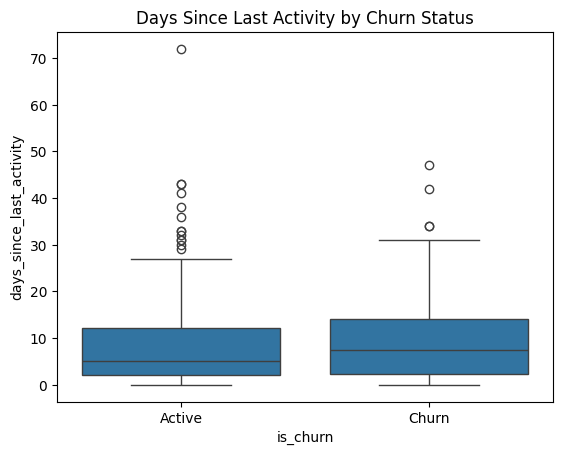

In [ ]:
sns.boxplot(
    data=df_model,
    x="is_churn",
    y="days_since_last_activity"
)

plt.xticks(
    [0, 1],
    ["Active", "Churn"]
)

plt.title("Days Since Last Activity by Churn Status")
plt.show()

In [ ]:
active = df_model.loc[
    df_model["is_churn"] == 0,
    "days_since_last_activity"
].dropna()

churn = df_model.loc[
    df_model["is_churn"] == 1,
    "days_since_last_activity"
].dropna()

stat, p_value = mannwhitneyu(
    active,
    churn,
    alternative="two-sided"
)

print("U statistic:", stat)
print("p-value:", p_value)

U statistic: 6127.5
p-value: 0.4610051241058575


Rumusan Hipotesis

$H_0 : \mu_1 = \mu_2$ (Tidak terdapat perbedaan median transaction_count antara pelanggan active dan churn)

$H_1 : \mu_1 \neq \mu_2$ (Terdapat perbedaan median transaction_count antara pelanggan active dan churn)

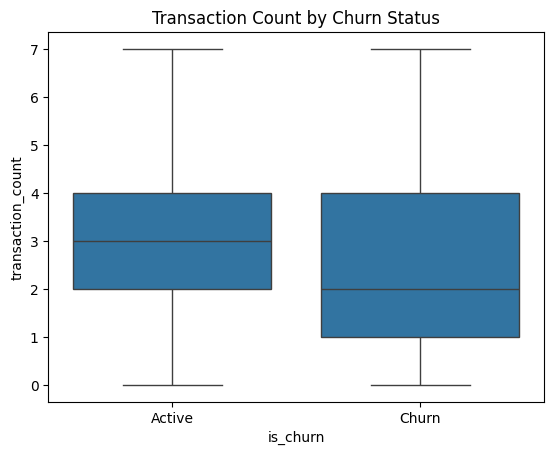

In [ ]:
sns.boxplot(
    data=df_model,
    x="is_churn",
    y="transaction_count"
)

plt.xticks(
    [0, 1],
    ["Active", "Churn"]
)

plt.title("Transaction Count by Churn Status")
plt.show()

In [ ]:
active = df_model.loc[
    df_model["is_churn"] == 0,
    "transaction_count"
].dropna()

churn = df_model.loc[
    df_model["is_churn"] == 1,
    "transaction_count"
].dropna()

stat, p_value = mannwhitneyu(
    active,
    churn,
    alternative="two-sided"
)

print("U statistic:", stat)
print("p-value:", p_value)

U statistic: 8039.5
p-value: 0.003002978007289067


Rumusan Hipotesis

$H_0 : \mu_1 = \mu_2$ (Tidak terdapat perbedaan median avg_transaction_amount antara pelanggan active dan churn)

$H_1 : \mu_1 \neq \mu_2$ (Terdapat perbedaan median avg_transaction_amount antara pelanggan active dan churn)

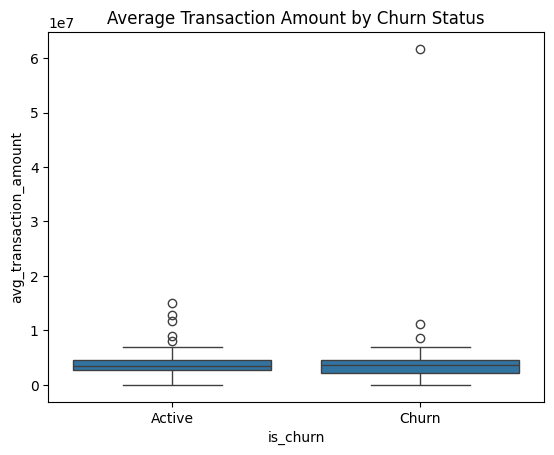

In [ ]:
sns.boxplot(
    data=df_model,
    x="is_churn",
    y="avg_transaction_amount"
)

plt.xticks(
    [0, 1],
    ["Active", "Churn"]
)

plt.title("Average Transaction Amount by Churn Status")
plt.show()

In [ ]:
active = df_model.loc[
    df_model["is_churn"] == 0,
    "avg_transaction_amount"
].dropna()

churn = df_model.loc[
    df_model["is_churn"] == 1,
    "avg_transaction_amount"
].dropna()

stat, p_value = mannwhitneyu(
    active,
    churn,
    alternative="two-sided"
)

print("U statistic:", stat)
print("p-value:", p_value)

U statistic: 6974.0
p-value: 0.37656506264416056


Rumusan Hipotesis

$H_0 : \mu_1 = \mu_2$ (Tidak terdapat perbedaan median total_sessions antara pelanggan active dan churn)

$H_1 : \mu_1 \neq \mu_2$ (Terdapat perbedaan median total_sessions antara pelanggan active dan churn)

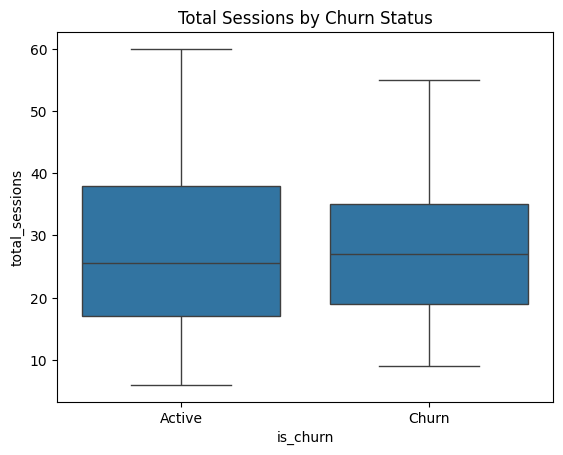

In [ ]:
sns.boxplot(
    data=df_model,
    x="is_churn",
    y="total_sessions"
)

plt.xticks(
    [0, 1],
    ["Active", "Churn"]
)

plt.title("Total Sessions by Churn Status")
plt.show()

In [ ]:
active = df_model.loc[
    df_model["is_churn"] == 0,
    "total_sessions"
].dropna()

churn = df_model.loc[
    df_model["is_churn"] == 1,
    "total_sessions"
].dropna()

stat, p_value = mannwhitneyu(
    active,
    churn,
    alternative="two-sided"
)

print("U statistic:", stat)
print("p-value:", p_value)

U statistic: 6360.0
p-value: 0.7715103404697692


Rumusan Hipotesis

$H_0 : \mu_1 = \mu_2$ (Tidak terdapat perbedaan median active_days antara pelanggan active dan churn)

$H_1 : \mu_1 \neq \mu_2$ (Terdapat perbedaan median active_days antara pelanggan active dan churn)

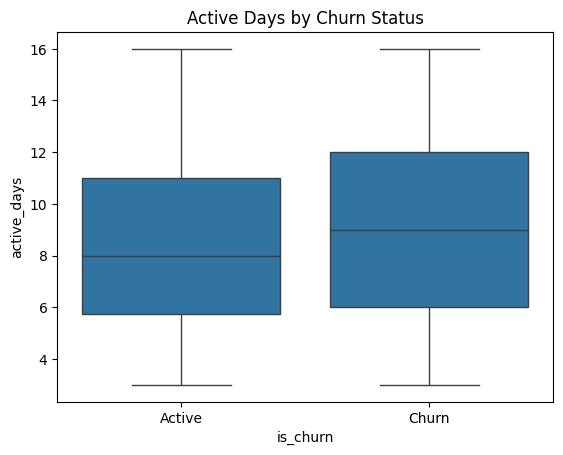

In [ ]:
sns.boxplot(
    data=df_model,
    x="is_churn",
    y="active_days"
)

plt.xticks(
    [0, 1],
    ["Active", "Churn"]
)

plt.title("Active Days by Churn Status")
plt.show()

In [ ]:
active = df_model.loc[
    df_model["is_churn"] == 0,
    "active_days"
].dropna()

churn = df_model.loc[
    df_model["is_churn"] == 1,
    "active_days"
].dropna()

stat, p_value = mannwhitneyu(
    active,
    churn,
    alternative="two-sided"
)

print("U statistic:", stat)
print("p-value:", p_value)

U statistic: 6214.0
p-value: 0.5672000173945005


- Pelanggan yang churn menunjukkan perbedaan yang signifikan dibandingkan dengan pelanggan aktif dalam transaction_count (seberapa sering customer bertransaksi).

- Perbedaan jumlah hari sejak aktivitas terakhir, nilai transaksi rata-rata, jumlah sesi, dan hari aktif tidak signifikan secara statistik.

## **Analyze Session Frequency, Transaction Amount, and Feature Usage**

satu user hanya dihitung satu kali per feature

In [ ]:
feature_user = pd.crosstab(
    activity_model["user_id"],
    activity_model["feature_used"]
)

feature_user = feature_user.gt(0).astype(int)

In [ ]:
feature_user.head(5)

feature_used,browse,loan_apply,payment,promo_click
user_id,,,,
1,0,1,1,1
2,1,1,1,1
3,1,1,1,1
4,1,1,1,1
5,1,1,0,0


In [ ]:
# Rebuild feature_user from the source activity_model to ensure a clean state on every execution
feature_user = pd.crosstab(
    activity_model["user_id"],
    activity_model["feature_used"]
)
feature_user = feature_user.gt(0).astype(int)

# Safely reset the index now that the state is clean
feature_user = feature_user.reset_index()

# Merge status to acquire churn labels
feature_user = feature_user.merge(
    status[["user_id", "is_churn"]],
    on="user_id",
    how="left"
)

# Calculate the percentage of feature adoption grouped by churn status
feature_usage = (
    feature_user
    .groupby("is_churn")
    [["browse", "loan_apply", "payment", "promo_click"]]
    .mean()
    * 100
)

feature_usage

,browse,loan_apply,payment,promo_click
is_churn,,,,
0,89.20,92.05,87.50,89.77
1,85.14,85.14,86.49,93.24


1. Pelanggan yang aktif memiliki tingkat pengajuan pinjaman (loan_apply) yang jauh lebih tinggi (92.05%) dibandingkan pelanggan yang churn (85.14%).
2. Pelanggan yang akhirnya churn justru memiliki interaksi klik promo yang lebih tinggi (93.24%) dibandingkan pelanggan aktif (89.77%). Hal ini bisa mengindikasikan bahwa kelompok pelanggan churn adalah promo hunters yang hanya aktif ketika ada insentif, atau mereka merasa kecewa setelah mengeklik promo karena syarat dan ketentuan yang tidak sesuai harapan.
3. Aktivitas pembayaran (payment) dan penjelajahan (browse) relatif stabil dan memiliki kemiripan persentase yang dekat di antara kedua kelompok, menandakan fitur ini digunakan secara mendasar oleh hampir seluruh basis pengguna.

### **Hypothesis Testing**

In [ ]:
from scipy.stats import chi2_contingency

In [ ]:
feature_results = []

feature_cols = [
    col for col in feature_user.columns
    if col not in ["user_id", "is_churn"]
]

for col in feature_cols:
    # Construct the correct contingency table crossing the feature use with churn status
    contingency_table = pd.crosstab(
        feature_user[col],
        feature_user["is_churn"]
    )

    chi2, p, dof, expected = chi2_contingency(contingency_table)

    feature_results.append({
        'feature': col,
        'chi2_statistic': chi2,
        'p_value': p
    })

feature_results = pd.DataFrame(feature_results)
feature_results

,feature,chi2_statistic,p_value
0,browse,0.48,0.49
1,loan_apply,2.05,0.15
2,payment,0.00,0.99
3,promo_click,0.39,0.53


Rumusan Hipotesis:

\begin{align*}
H_0 &: \chi^2 = 0 \quad (\text{Tidak ada asosiasi antara penggunaan fitur payment dengan status pelanggan}) \\
H_1 &: \chi^2 \neq 0 \quad (\text{Ada asosiasi antara penggunaan fitur payment dengan status pelanggan.})
\end{align*}


In [ ]:
table = pd.crosstab(
    feature_user["payment"],
    feature_user["is_churn"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("p-value:", p)

Chi-square: 0.00013482959476365585
p-value: 0.9907354801343817


Rumusan Hipotesis:

\begin{align*}
H_0 &: \chi^2 = 0 \quad (\text{Tidak ada asosiasi antara penggunaan fitur browse dengan status pelanggan}) \\
H_1 &: \chi^2 \neq 0 \quad (\text{Ada asosiasi antara penggunaan fitur browse dengan status pelanggan.})
\end{align*}


In [ ]:
table = pd.crosstab(
    feature_user["browse"],
    feature_user["is_churn"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("p-value:", p)

Chi-square: 0.4770476183828458
p-value: 0.4897626763754598


Rumusan Hipotesis:

\begin{align*}
H_0 &: \chi^2 = 0 \quad (\text{Tidak ada asosiasi antara penggunaan fitur loan_apply dengan status pelanggan}) \\
H_1 &: \chi^2 \neq 0 \quad (\text{Ada asosiasi antara penggunaan fitur loan_apply dengan status pelanggan.})
\end{align*}


In [ ]:
table = pd.crosstab(
    feature_user["loan_apply"],
    feature_user["is_churn"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("p-value:", p)

Chi-square: 2.049634862134862
p-value: 0.1522426985526992


Rumusan Hipotesis:

\begin{align*}
H_0 &: \chi^2 = 0 \quad (\text{Tidak ada asosiasi antara penggunaan fitur promo_click dengan status pelanggan}) \\
H_1 &: \chi^2 \neq 0 \quad (\text{Ada asosiasi antara penggunaan fitur promo_click dengan status pelanggan.})
\end{align*}


In [ ]:
table = pd.crosstab(
    feature_user["promo_click"],
    feature_user["is_churn"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("p-value:", p)

Chi-square: 0.39313112868226835
p-value: 0.5306581224387409


- Tingkat adopsi fitur umumnya tinggi baik di kalangan pelanggan aktif maupun pelanggan yang churn. Mayoritas pelanggan sama-sama menggunakan atau mencoba fitur tersebut.

- Meski demikian, tidak terbukti secara statistik jika ada hubungan antara penggunaan fitur dengan status pelanggan.

- Perilaku penggunaan fitur pada pelanggan aktif dan pelanggan churn terlalu mirip, sehingga fitur tersebut tidak bisa menjadi pembeda apakah seorang pelanggan akan bertahan atau pergi.

## **Identify Characteristics of Customer Churn**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

### **Correlation Analysis**

In [ ]:
numeric_cols = [
    'age',
    'tenure_days',
    'transaction_count',
    'total_tx_amount',
    'avg_transaction_amount',
    'total_sessions',
    'avg_sessions',
    'active_days',
    'activity_events',
    'days_since_last_activity'
]

# Include 'is_churn' in the subset so it is available in the calculated correlation matrix
correlation = df_model[numeric_cols + ['is_churn']].corr()['is_churn'].sort_values(ascending=False)

print("--- Correlation ---")
print(correlation)

--- Correlation ---
is_churn                    1.00
avg_transaction_amount      0.05
avg_sessions                0.04
active_days                 0.03
days_since_last_activity    0.03
total_sessions              0.01
tenure_days                 0.01
activity_events             0.00
age                        -0.01
total_tx_amount            -0.07
transaction_count          -0.17
Name: is_churn, dtype: float64


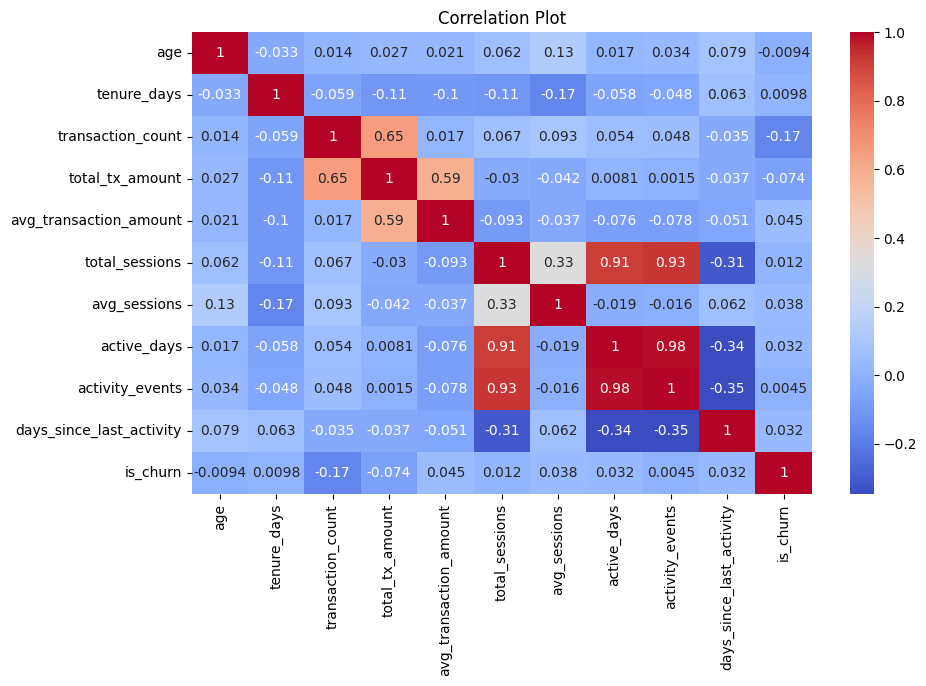

In [ ]:
# Plot
plt.figure(figsize=(10, 6))
sns.heatmap(df_model[numeric_cols + ['is_churn']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Plot')
plt.show()

### **Hypothesis Testing**

In [ ]:
df_model.groupby("is_churn")[
    "age"
].agg(["count", "median", "mean"])

,count,median,mean
is_churn,,,
0,176,40.00,38.66
1,74,41.50,38.45


Rumusan Hipotesis

$H_0 : \mu_1 = \mu_2$ (Tidak terdapat perbedaan median age antara pelanggan active dan churn)

$H_1 : \mu_1 \neq \mu_2$ (Terdapat perbedaan median age antara pelanggan active dan churn)

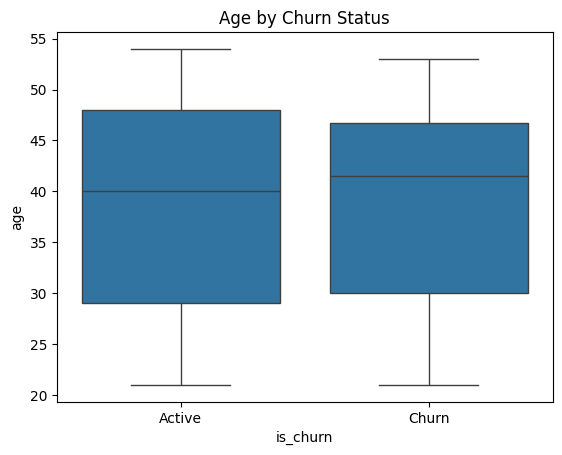

In [ ]:
sns.boxplot(
    data=df_model,
    x="is_churn",
    y="age"
)

plt.xticks(
    [0, 1],
    ["Active", "Churn"]
)

plt.title("Age by Churn Status")
plt.show()

In [ ]:
active = df_model.loc[
    df_model["is_churn"] == 0,
    "age"
].dropna()

churn = df_model.loc[
    df_model["is_churn"] == 1,
    "age"
].dropna()

stat, p_value = mannwhitneyu(
    active,
    churn,
    alternative="two-sided"
)

print("U statistic:", stat)
print("p-value:", p_value)

U statistic: 6596.0
p-value: 0.8727957318446912


In [ ]:
city_churn = pd.crosstab(
    df_model["city"],
    df_model["is_churn"],
    normalize="index"
) * 100

city_churn

is_churn,0,1
city,,
Bandung,70.42,29.58
Jakarta,69.16,30.84
Surabaya,72.22,27.78


In [ ]:
# calculate size
df_model.groupby("city")["is_churn"].size()

,is_churn
city,
Bandung,71
Jakarta,107
Surabaya,72


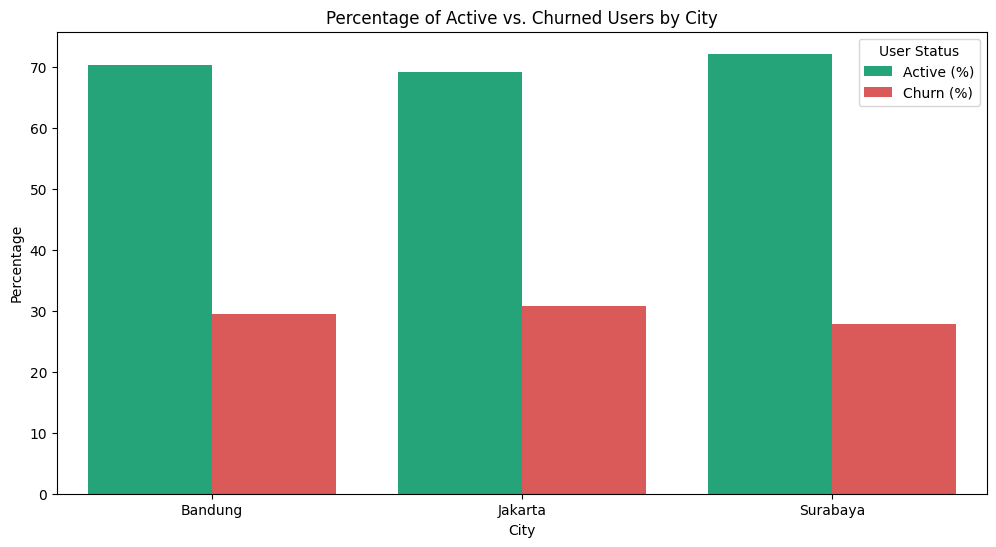

In [ ]:
# Visual
plt.figure(figsize=(12, 6))

# Melt the DataFrame to long format for plotting percentages of active and churn
plot_data = city_churn.reset_index().melt(
    id_vars='city',
    var_name='churn_status',
    value_name='percentage'
)

# Map numeric churn_status to descriptive labels for better readability
plot_data['churn_status'] = plot_data['churn_status'].map({0: 'Active (%)', 1: 'Churn (%)'})

sns.barplot(
    data=plot_data,
    x="city",
    y="percentage",
    hue="churn_status",
    palette={'Active (%)': '#10b981', 'Churn (%)': '#ef4444'}
)

plt.title('Percentage of Active vs. Churned Users by City')
plt.xlabel('City')
plt.ylabel('Percentage')
plt.legend(title='User Status')
plt.show()

Rumusan Hipotesis:

\begin{align*}
H_0 &: \pi_{\text{churn, Bandung}} = \pi_{\text{churn, Jakarta}} = \pi_{\text{churn, Surabaya}} \\
H_1 &: \text{Minimal ada satu pasang kota yang memiliki proporsi } \textit{churn} \text{ yang berbeda.}
\end{align*}


In [ ]:
# Chi square
table = pd.crosstab(
    df_model["city"],
    df_model["is_churn"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("p-value:", p)

Chi-square: 0.1938404803022416
p-value: 0.9076283955500173


In [ ]:
acquisition_channel_churn = pd.crosstab(
    df_model["acquisition_channel"],
    df_model["is_churn"],
    normalize="index"
) * 100

acquisition_channel_churn

is_churn,0,1
acquisition_channel,,
Ads,71.43,28.57
Affiliate,72.06,27.94
Organic,69.49,30.51
Referral,68.66,31.34


In [ ]:
# calculate size
df_model.groupby("acquisition_channel")["is_churn"].size()

,is_churn
acquisition_channel,
Ads,56
Affiliate,68
Organic,59
Referral,67


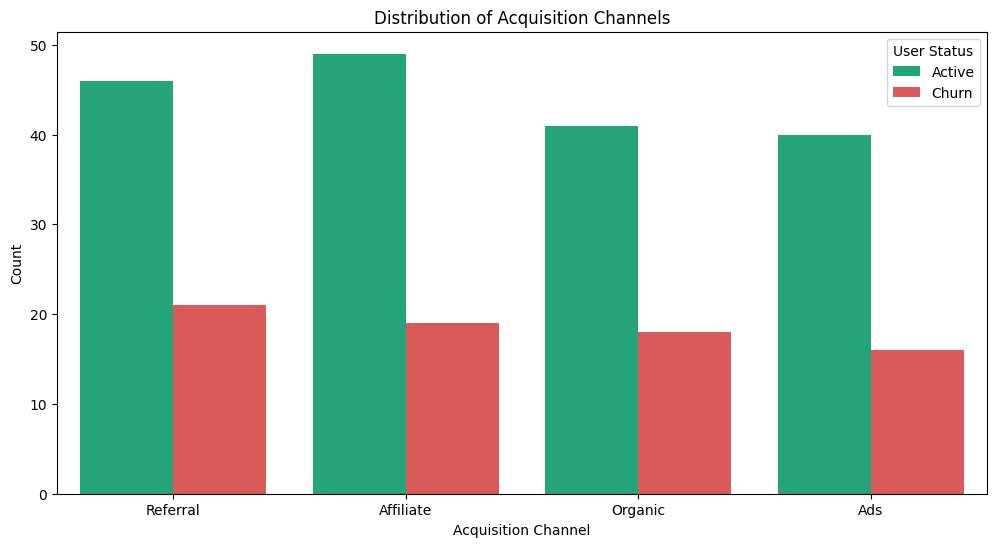

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Distribution channel acquisition
plt.figure(figsize=(12, 6))

# plot
sns.countplot(
    data=df_model,
    x="acquisition_channel",
    hue="is_churn",
    palette={0: '#10b981', 1: '#ef4444'}
)

plt.title('Distribution of Acquisition Channels')
plt.xlabel('Acquisition Channel')
plt.ylabel('Count')
plt.legend(title='User Status', labels=['Active', 'Churn'])
plt.show()

Text(0.5, 0, 'Acquisition Channel')

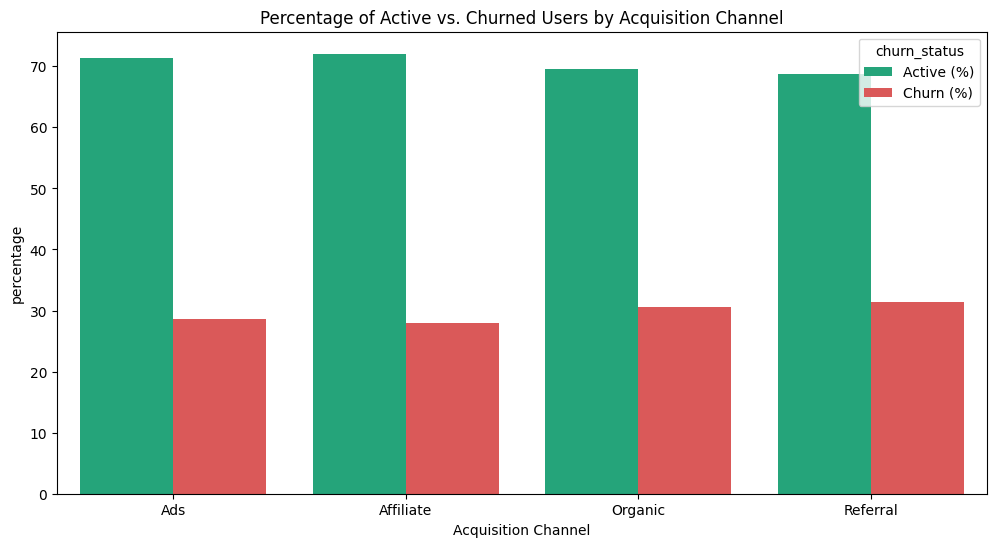

In [ ]:
# Visual
plt.figure(figsize=(12, 6))

# Melt the DataFrame to long format for plotting percentages of active and churn
plot_data = acquisition_channel_churn.reset_index().melt(
    id_vars='acquisition_channel',
    var_name='churn_status',
    value_name='percentage',
    value_vars=[0, 1]
)

# Map numeric churn_status to descriptive labels for better readability
plot_data['churn_status'] = plot_data['churn_status'].map({0: 'Active (%)', 1: 'Churn (%)'})

sns.barplot(
    data=plot_data,
    x="acquisition_channel",
    y="percentage",
    hue="churn_status",
    palette={'Active (%)': '#10b981', 'Churn (%)': '#ef4444'}
)

plt.title('Percentage of Active vs. Churned Users by Acquisition Channel')
plt.xlabel('Acquisition Channel')

Rumusan Hipotesis:

\begin{align*}
H_0 &: \pi_{\text{churn, Ads}} = \pi_{\text{churn, Affiliate}} = \pi_{\text{churn, Organic}} = \pi_{\text{churn, Referral}} \\
H_1 &: \text{Minimal ada satu pasang acquisition channel yang memiliki proporsi } \textit{churn} \text{ yang berbeda.}
\end{align*}


In [ ]:
# Chi square
table = pd.crosstab(
    df_model["acquisition_channel"],
    df_model["is_churn"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("p-value:", p)

Chi-square: 0.2393037700013229
p-value: 0.9710079757177418


- Di berbagai kota (Jakarta, Bandung, dan Surabaya), tingkat churn rate berada di angka yang relatif seragam (27% - 30%).
- Sama halnya dengan acqusition channcel (Ads, Affiliate, Organic, Referral) yang variasinya tidak terlalu besar (27% - 31%).
- Perbedaan angka antar kota maupun antar saluran tergolong sangat kecil sehingga tidak signifikan secara statistik, yang berarti perilaku pelanggan di wilayah dan saluran tersebut relatif mirip.

In [ ]:
df_model['signup_cohort'] = (
    df_model['signup_date']
    .dt.to_period('M')
    .astype(str)
)

In [ ]:
cohort_churn = (
    df_model
    .groupby(
        ['acquisition_channel', 'signup_cohort']
    )
    .agg(
        total_users=('user_id', 'count'),
        churn_users=('is_churn', 'sum')
    )
    .reset_index()
)

cohort_churn['churn_rate'] = (
    cohort_churn['churn_users'] /
    cohort_churn['total_users'] * 100
)

cohort_churn

,acquisition_channel,signup_cohort,total_users,churn_users,churn_rate
0,Ads,2024-01,6,2,33.33
1,Ads,2024-02,6,2,33.33
2,Ads,2024-03,8,6,75.00
3,Ads,2024-04,14,2,14.29
4,Ads,2024-05,2,1,50.00
5,Ads,2024-06,5,1,20.00
6,Ads,2024-07,6,0,0.00
7,Ads,2024-08,8,2,25.00
8,Ads,2024-09,1,0,0.00
9,Affiliate,2024-01,10,1,10.00


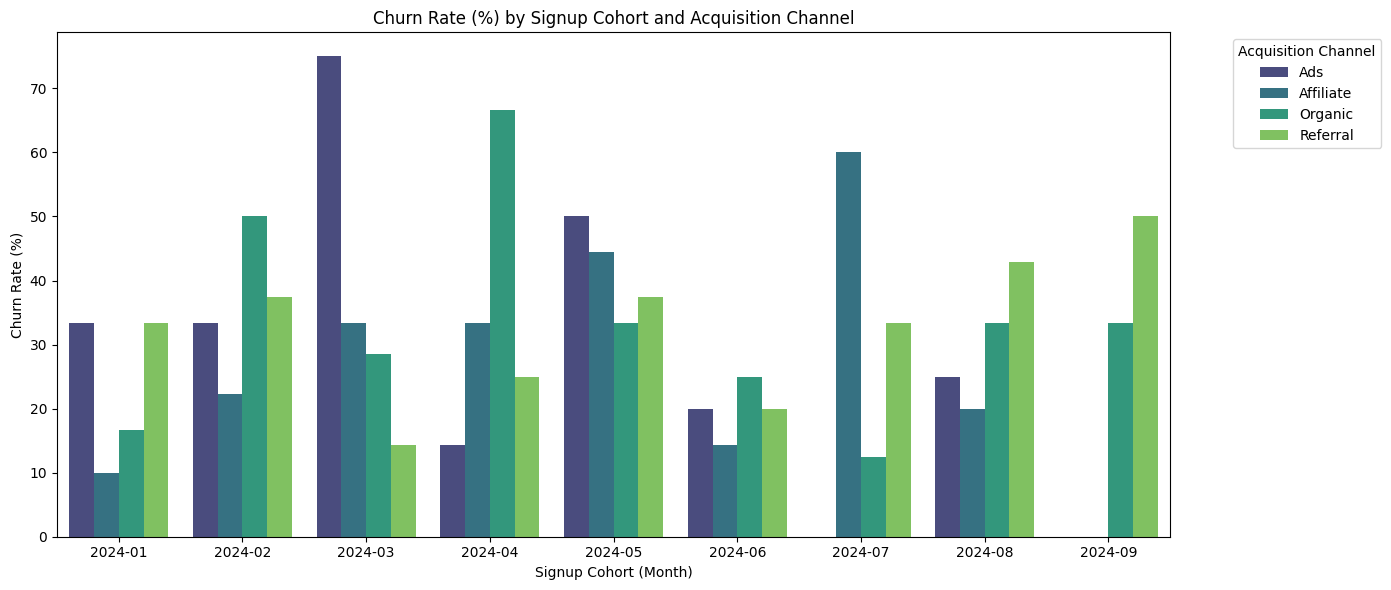

In [ ]:
# Visualize
plt.figure(figsize=(14, 6))

# Melt the DataFrame to long format for plotting
plot_data = cohort_churn.melt(
    id_vars=['acquisition_channel', 'signup_cohort'],
    var_name='churn_status',
    value_name='percentage',
    value_vars=['churn_rate']
)

# Create the bar plot
sns.barplot(
    data=plot_data,
    x='signup_cohort',
    y='percentage',
    hue='acquisition_channel',
    palette='viridis'
)

plt.title('Churn Rate (%) by Signup Cohort and Acquisition Channel')
plt.xlabel('Signup Cohort (Month)')
plt.ylabel('Churn Rate (%)')
plt.legend(title='Acquisition Channel', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### **Visualization**

In [ ]:
# 1. Rentang churn date
print("Min churn date:", status['churn_date'].min())
print("Max churn date:", status['churn_date'].max())

# 2. Jumlah churn berdasarkan bulan
print(
    status[
        status['churn_date'].notna()
    ]
    .assign(
        churn_month=lambda x: pd.to_datetime(x['churn_date']).dt.to_period('M')
    )
    ['churn_month']
    .value_counts()
    .sort_index()
)

# 3. Contoh data status
print(
    status[['user_id', 'is_churn', 'churn_date']]
    .sort_values('churn_date')
    .head(20)
)

Min churn date: 2025-01-04 00:00:00
Max churn date: 2025-03-31 00:00:00
churn_month
2025-01    33
2025-02    16
2025-03    25
Freq: M, Name: count, dtype: int64
     user_id  is_churn churn_date
241      242         1 2025-01-04
13        14         1 2025-01-04
20        21         1 2025-01-04
35        36         1 2025-01-04
119      120         1 2025-01-07
144      145         1 2025-01-07
210      211         1 2025-01-08
11        12         1 2025-01-08
147      148         1 2025-01-09
42        43         1 2025-01-10
86        87         1 2025-01-11
140      141         1 2025-01-11
61        62         1 2025-01-12
52        53         1 2025-01-12
176      177         1 2025-01-17
110      111         1 2025-01-18
183      184         1 2025-01-19
165      166         1 2025-01-19
91        92         1 2025-01-20
184      185         1 2025-01-20


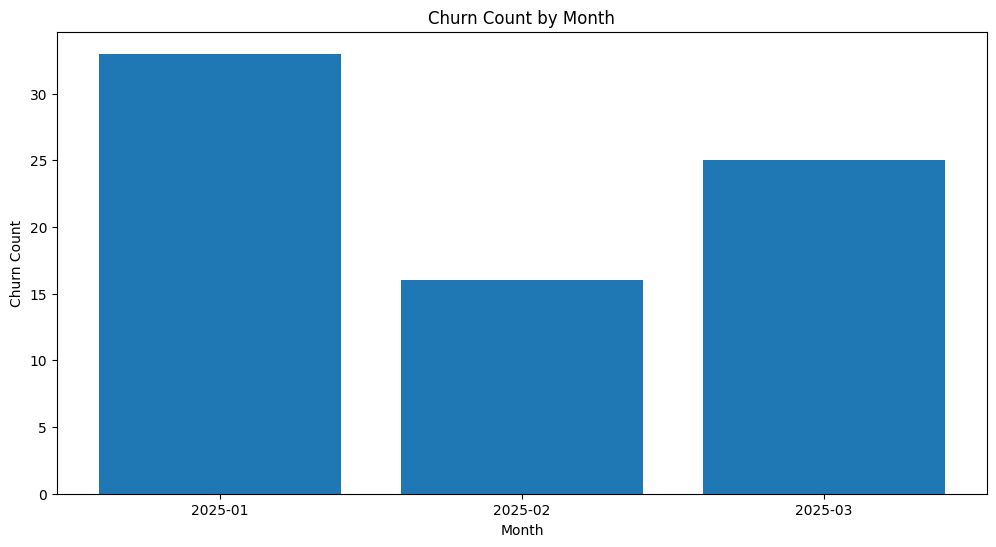

In [ ]:
# PLOT
plt.figure(figsize=(12, 6))

# Permanently create 'churn_month' column in status dataframe
status['churn_month'] = pd.to_datetime(status['churn_date']).dt.to_period('M')

# Sort by index (chronologically) so the plot reads naturally from January to March
churn_counts = status['churn_month'].value_counts().sort_index()

plt.bar(
    churn_counts.index.astype(str),
    churn_counts.values,
)

plt.title('Churn Count by Month')
plt.xlabel('Month')
plt.ylabel('Churn Count')

plt.show()

In [ ]:
# 1. Pastikan kolom tanggal bertipe datetime dan gabungkan data signup_date sebagai join_date
status['churn_date'] = pd.to_datetime(status['churn_date'])

# Ambil signup_date dari dataframe user sebagai pengganti join_date
if 'join_date' not in status.columns:
    status = status.merge(user[['user_id', 'signup_date']], on='user_id', how='left')
    status = status.rename(columns={'signup_date': 'join_date'})

status['join_date'] = pd.to_datetime(status['join_date'])

# 2. Buat kolom periode bulan berdasarkan churn_date
status['churn_month'] = status['churn_date'].dt.to_period('M')

# 3. Hitung JUMLAH CHURN per bulan
churn_per_bulan = status[status['churn_date'].notna()]['churn_month'].value_counts().sort_index()

# 4. Hitung TOTAL PELANGGAN AKTIF di awal bulan
pelanggan_aktif_per_bulan = {}
semua_bulan = churn_per_bulan.index

for bulan in semua_bulan:
    awal_bulan = bulan.start_time

    # Filter pelanggan yang sudah join SEBELUM awal bulan ini DAN belum churn (atau churn SETELAH awal bulan ini)
    aktif = status[
        (status['join_date'] < awal_bulan) &
        ((status['churn_date'].isna()) | (status['churn_date'] >= awal_bulan))
    ]
    pelanggan_aktif_per_bulan[bulan] = len(aktif)

# Ubah ke Series agar mudah dihitung
total_aktif = pd.Series(pelanggan_aktif_per_bulan)

# 5. Hitung CHURN RATE (Jumlah Churn / Total Aktif Awal Bulan) * 100
churn_rate_bulanan = (churn_per_bulan / total_aktif) * 100

# 6. Gabungkan hasil ke dalam satu DataFrame agar rapi
df_churn_analysis = pd.DataFrame({
    'Jumlah Churn': churn_per_bulan,
    'Total Pelanggan Aktif': total_aktif,
    'Churn Rate (%)': churn_rate_bulanan.round(2)
}).fillna(0)

print(df_churn_analysis)

         Jumlah Churn  Total Pelanggan Aktif  Churn Rate (%)
2025-01            33                    250           13.20
2025-02            16                    217            7.37
2025-03            25                    201           12.44


In [ ]:
# ANALISIS 1: Rata-rata Metrik Perilaku per Bulan Churn
# =====================================================================
print("--- RATA-RATA METRIK PERILAKU PER BULAN CHURN ---")
metrics = [
    'tenure_days',
    'days_since_last_activity',
    'active_days',
    'total_sessions',
    'activity_events',
    'transaction_count',
    'total_tx_amount',
    'avg_transaction_amount'
]

# Create 'churn_month' in df_model derived from 'churn_date'
df_model['churn_month'] = pd.to_datetime(df_model['churn_date']).dt.to_period('M')

# Compare per churn month
df_model.groupby('churn_month')[metrics].mean()

--- RATA-RATA METRIK PERILAKU PER BULAN CHURN ---


,tenure_days,days_since_last_activity,active_days,total_sessions,activity_events,transaction_count,total_tx_amount,avg_transaction_amount
churn_month,,,,,,,,
2025-01,333.97,9.03,8.64,26.52,8.94,2.70,11745062.91,3809933.17
2025-02,342.12,8.94,9.38,30.69,9.75,2.44,8405503.44,3152856.51
2025-03,321.72,12.00,8.68,26.80,8.84,2.56,11121875.28,5328976.62


In [ ]:
# ANALISIS 2: Fitur yang Paling Sering Digunakan Sebelum Churn
# =====================================================================
print("\n--- FITUR YANG PALING SERING DIGUNAKAN PER BULAN CHURN ---")
# 'churn_month', 'most_used_feature'
feature_analysis = df_model.groupby('churn_month')['most_used_feature'].value_counts().unstack(fill_value=0)
feature_analysis
# Show percentage
feature_analysis_percentage = feature_analysis.div(feature_analysis.sum(axis=1), axis=0) * 100
feature_analysis_percentage


--- FITUR YANG PALING SERING DIGUNAKAN PER BULAN CHURN ---


most_used_feature,browse,loan_apply,payment,promo_click
churn_month,,,,
2025-01,36.36,30.30,18.18,15.15
2025-02,25.00,43.75,18.75,12.50
2025-03,12.00,36.00,24.00,28.00


<Figure size 1200x600 with 0 Axes>

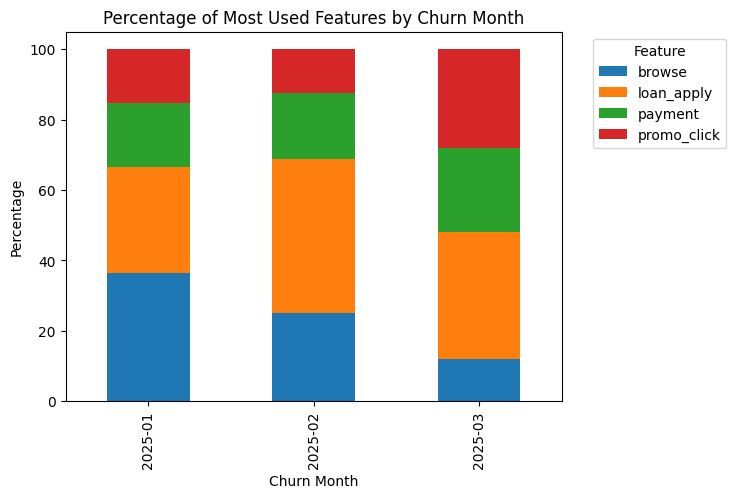

In [ ]:
# Visual plot
plt.figure(figsize=(12, 6))

# Plot
feature_analysis_percentage.plot(kind='bar', stacked=True)

plt.title('Percentage of Most Used Features by Churn Month')
plt.xlabel('Churn Month')
plt.ylabel('Percentage')
plt.legend(title='Feature', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

- Penurunan Drastis Fitur Browse (36.36% → 12.00%): Pada bulan Januari, kontributor churn terbesar adalah pengguna yang hanya sekadar melihat-lihat produk. Namun pada bulan Maret, angka ini turun tajam. Artinya, pelanggan yang churn bukan lagi tipe pengguna kasual yang sekadar melihat-lihat produk.

- Lonjakan Masalah pada Loan_Apply (30.30% → 36.00%, Puncak di Februari 43.75%): Fitur pengajuan pinjaman secara konsisten menjadi aktivitas tertinggi pelanggan yang churn di bulan Februari dan Maret.

- Kenaikan Tajam pada Promo_Click (15.15% → 28.00%): Pada bulan Maret, hampir sepertiga pelanggan yang churn adalah mereka yang aktif mencari atau mengeklik promo.

In [ ]:
# ANALISIS 3: Saluran Akuisisi (Acquisition Channel)
# =====================================================================
print("\n--- DISTRIBUSI SALURAN AKUISISI PER BULAN CHURN ---")
# 'churn_month', 'acquisition_channel'
channel_analysis = df_model.groupby('churn_month')['acquisition_channel'].value_counts().unstack(fill_value=0)
channel_analysis
# Tabel to show churn_month, acquisition channel, and total per month
channel_analysis_total = channel_analysis.copy()
channel_analysis_total['total'] = channel_analysis.sum(axis=1)
channel_analysis_total


--- DISTRIBUSI SALURAN AKUISISI PER BULAN CHURN ---


acquisition_channel,Ads,Affiliate,Organic,Referral,total
churn_month,,,,,
2025-01,5,10,7,11,33
2025-02,4,3,5,4,16
2025-03,7,6,6,6,25


<Figure size 1200x600 with 0 Axes>

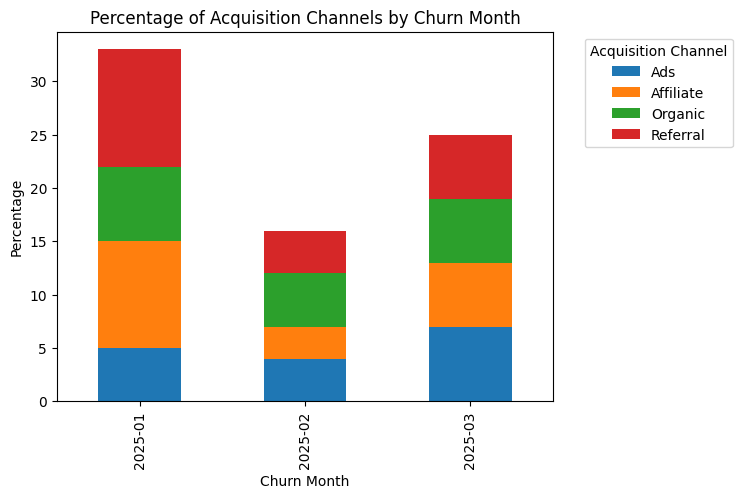

In [ ]:
# Visual plot
plt.figure(figsize=(12, 6))

# Plot
channel_analysis.plot(kind='bar', stacked=True)

plt.title('Percentage of Acquisition Channels by Churn Month')
plt.xlabel('Churn Month')
plt.ylabel('Percentage')
plt.legend(title='Acquisition Channel', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

- Saluran Churn Tertinggi: Saluran Referral menyumbang angka kehilangan pelanggan terbesar dengan total 21 pelanggan, disusul oleh Affiliate sebanyak 19 pelanggan.

- Saluran Churn Terendah: Saluran Ads memiliki performa retensi yang relatif lebih baik dengan total kehilangan 16 pelanggan.

- Tren Bulanan: Kehilangan pelanggan sempat menurun drastis pada bulan Februari (16 pelanggan), namun kembali meningkat pada bulan Maret menjadi 25 pelanggan.

- Referral dan Affiliate menyumbang churn terbesar (40 pelanggan dari total 74). Maknanya, pelanggan yang datang karena ajakan teman (referral) atau promosi afiliasi sangat mudah pergi setelah masa promo atau insentif mereka habis.

## **Simple Segmentation (High-Risk Active Customer vs Low-Risk Active Customer)**

In [ ]:
# ============================================================
# SIMPLE RULE-BASED BEHAVIORAL SEGMENTATION
# Population: ACTIVE CUSTOMERS ONLY
# ============================================================

# ------------------------------------------------------------
# 1. Filter hanya customer yang masih aktif
# ------------------------------------------------------------
df_active = df_model[df_model['is_churn'] == 0].copy()

print("Total active customers:", len(df_active))


# ------------------------------------------------------------
# 2. Buat behavioral risk flags
# ------------------------------------------------------------

# Signal 1: Recency
# Customer tidak melakukan aktivitas selama >= 30 hari
df_active['flag_high_recency'] = (
    df_active['days_since_last_activity'] >= 30
)

# Signal 2: Low repeat borrowing
# Customer memiliki transaction_count <= 2
df_active['flag_low_transaction'] = (
    df_active['transaction_count'] <= 2
)


# ------------------------------------------------------------
# 3. Simple Risk Segmentation
# ------------------------------------------------------------
#
# High-Risk Active:
#   - inactivity >= 30 hari
#     ATAU
#   - low repeat borrowing (transaction_count <= 2)
#
# Low-Risk Active:
#   - tidak memenuhi kedua kondisi tersebut
#
# NOTE:
# Threshold 30 hari dan transaction_count <= 2 merupakan
# heuristic baseline dan nantinya perlu divalidasi
# terhadap future churn.
# ------------------------------------------------------------

df_active['risk_segment'] = np.where(
    (
        df_active['flag_high_recency']
        |
        df_active['flag_low_transaction']
    ),
    'High-Risk Active',
    'Low-Risk Active'
)


# ------------------------------------------------------------
# 4. Summary jumlah customer
# ------------------------------------------------------------

segment_summary = (
    df_active['risk_segment']
    .value_counts()
    .rename_axis('Risk Segment')
    .reset_index(name='User Count')
)

segment_summary['Percentage (%)'] = (
    segment_summary['User Count']
    / len(df_active)
    * 100
)

print("\n==============================================")
print("ACTIVE CUSTOMER RISK SEGMENTATION")
print("==============================================")
print(segment_summary)


# ------------------------------------------------------------
# 5. Pastikan total customer = 176
# ------------------------------------------------------------

print("\nTotal segmented active customers:",
      segment_summary['User Count'].sum())


# ------------------------------------------------------------
# 6. Breakdown berdasarkan masing-masing risk signal
# ------------------------------------------------------------

signal_summary = pd.DataFrame({
    'Risk Signal': [
        'Inactive >= 30 days',
        'Transaction count <= 2',
        'Both signals',
        'Neither signal'
    ],
    'User Count': [
        df_active['flag_high_recency'].sum(),
        df_active['flag_low_transaction'].sum(),
        (
            df_active['flag_high_recency']
            & df_active['flag_low_transaction']
        ).sum(),
        (
            ~df_active['flag_high_recency']
            & ~df_active['flag_low_transaction']
        ).sum()
    ]
})

signal_summary['Percentage (%)'] = (
    signal_summary['User Count']
    / len(df_active)
    * 100
)

print("\n==============================================")
print("RISK SIGNAL BREAKDOWN")
print("==============================================")
print(signal_summary)


# ------------------------------------------------------------
# 7. Profiling masing-masing segment
# ------------------------------------------------------------

profile = (
    df_active
    .groupby('risk_segment')
    .agg(
        user_count=('user_id', 'count'),
        avg_transaction_count=('transaction_count', 'mean'),
        median_transaction_count=('transaction_count', 'median'),
        avg_days_since_activity=('days_since_last_activity', 'mean'),
        median_days_since_activity=('days_since_last_activity', 'median'),
        avg_total_sessions=('total_sessions', 'mean'),
        median_total_sessions=('total_sessions', 'median'),
        avg_active_days=('active_days', 'mean'),
        median_active_days=('active_days', 'median')
    )
    .reset_index()
)

profile['percentage_of_active (%)'] = (
    profile['user_count']
    / len(df_active)
    * 100
)

print("\n==============================================")
print("SEGMENT PROFILE")
print("==============================================")
print(profile)

Total active customers: 176

ACTIVE CUSTOMER RISK SEGMENTATION
       Risk Segment  User Count  Percentage (%)
0   Low-Risk Active         100           56.82
1  High-Risk Active          76           43.18

Total segmented active customers: 176

RISK SIGNAL BREAKDOWN
              Risk Signal  User Count  Percentage (%)
0     Inactive >= 30 days          12            6.82
1  Transaction count <= 2          68           38.64
2            Both signals           4            2.27
3          Neither signal         100           56.82

SEGMENT PROFILE
       risk_segment  user_count  avg_transaction_count  \
0  High-Risk Active          76                   1.87   
1   Low-Risk Active         100                   4.26   

   median_transaction_count  avg_days_since_activity  \
0                      2.00                    12.18   
1                      4.00                     7.07   

   median_days_since_activity  avg_total_sessions  median_total_sessions  \
0                       

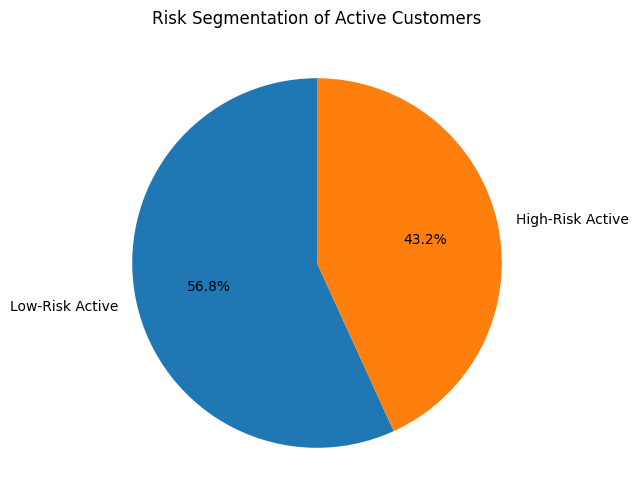

In [ ]:
# PLOT ACTIVE CUSTOMER RISK SEGMENTATION
plt.figure(figsize=(6, 6))
plt.pie(
    segment_summary['User Count'],
    labels=segment_summary['Risk Segment'],
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Risk Segmentation of Active Customers')
plt.show()

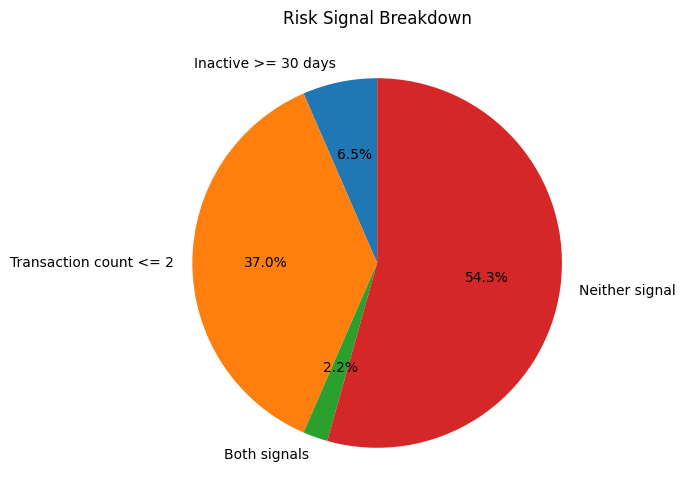

In [ ]:
# PLOT RISK SIGNAL BREAKDOWN
plt.figure(figsize=(6, 6))
plt.pie(
    signal_summary['User Count'],
    labels=signal_summary['Risk Signal'],
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Risk Signal Breakdown')
plt.show()

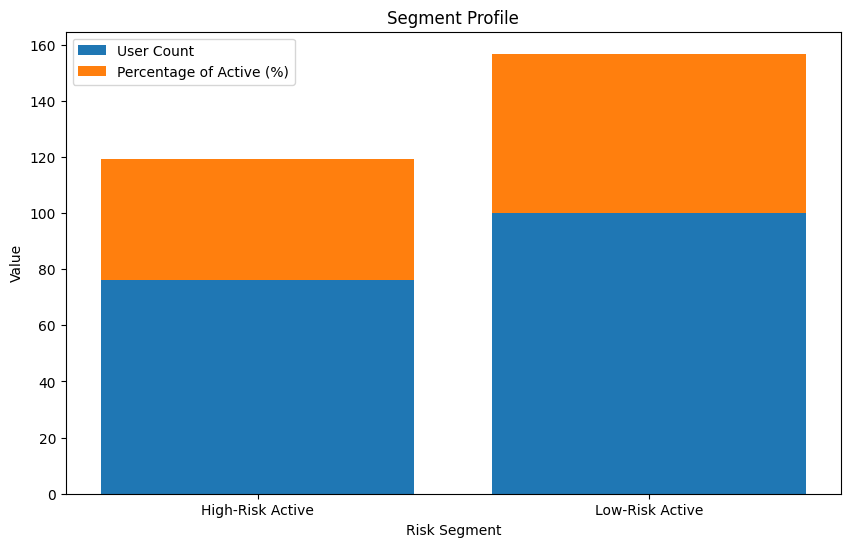

In [ ]:
# PLOT SEGMENT PROFILE
plt.figure(figsize=(10, 6))
plt.bar(
    profile['risk_segment'],
    profile['user_count'],
    label='User Count'
)
plt.bar(
    profile['risk_segment'],
    profile['percentage_of_active (%)'],
    bottom=profile['user_count'],
    label='Percentage of Active (%)'
)
plt.xlabel('Risk Segment')
plt.ylabel('Value')
plt.title('Segment Profile')
plt.legend()
plt.show()

In [ ]:
# Logika Penentuan Segmen Risiko untuk Pengguna Aktif (is_churn == 0)
def classify_risk(row):
    if row['is_churn'] == 1:
        return 'Already Churned'

    # Pengguna Aktif dengan Sinyal Bahaya:
    # Inaktif > 30 hari ATAU (Sesi Rendah DAN Pinjaman <= 2)
    if row['days_since_last_activity'] >= 30 or (row['total_sessions'] < 5 and row['loan_count'] <= 2):
        return 'High-Risk Active'
    else:
        return 'Low-Risk Active'

df_master['risk_segment'] = df_master.apply(classify_risk, axis=1)

# Summary Hasil Segmentasi
segment_counts = df_master['risk_segment'].value_counts().reset_index()
segment_counts.columns = ['Risk Segment', 'User Count']
segment_counts['Percentage (%)'] = (segment_counts['User Count'] / len(df_master)) * 100

print("--- Ringkasan Segmentasi Pengguna ---")
print(segment_counts)

--- Ringkasan Segmentasi Pengguna ---
       Risk Segment  User Count  Percentage (%)
0  High-Risk Active         108           43.20
1   Already Churned          74           29.60
2   Low-Risk Active          68           27.20


Text(0.5, 1.0, 'Ringkasan Segmentasi Pengguna')

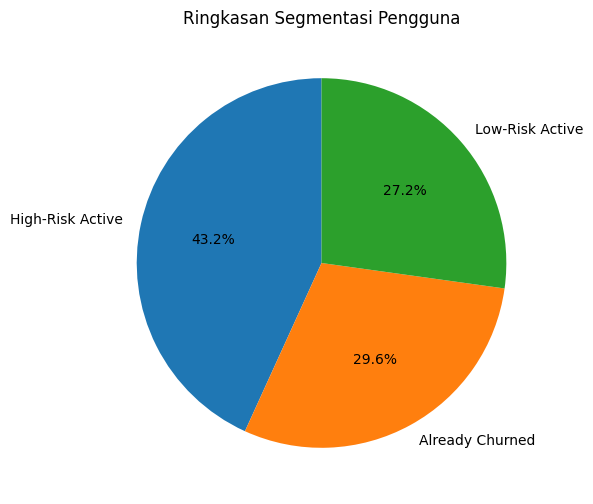

In [ ]:
# PIE CHART
plt.figure(figsize=(6, 6))
plt.pie(segment_counts['User Count'], labels=segment_counts['Risk Segment'], autopct='%1.1f%%', startangle=90)
plt.title('Ringkasan Segmentasi Pengguna')

# **MODELLING**

In [ ]:
from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

import matplotlib.pyplot as plt

In [ ]:
df_model

,user_id,signup_date,acquisition_channel,age,city,is_churn,churn_date,total_sessions,avg_sessions,active_days,activity_events,transaction_count,total_tx_amount,avg_transaction_amount,most_used_feature,last_activity_date,days_since_last_activity,tenure_days,signup_cohort,churn_month
0,1,2024-01-01,Referral,33.00,Jakarta,0,NaT,11,2.20,5,5,5.00,22648603.00,4529720.60,payment,2025-03-26,5,455,2024-01,NaT
1,2,2024-01-02,Affiliate,23.00,Bandung,0,NaT,32,2.91,10,11,5.00,15720762.00,3144152.40,browse,2025-03-23,8,454,2024-01,NaT
2,3,2024-01-03,Organic,26.00,Jakarta,0,NaT,37,3.08,11,12,4.00,9176843.00,2294210.75,browse,2025-03-25,6,453,2024-01,NaT
3,4,2024-01-04,Referral,28.00,Bandung,0,NaT,41,2.93,13,14,1.00,1076778.00,1076778.00,loan_apply,2025-03-31,0,452,2024-01,NaT
4,5,2024-01-05,Referral,47.00,Bandung,0,NaT,8,2.00,4,4,3.00,15024212.00,5008070.67,loan_apply,2025-03-09,22,451,2024-01,NaT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
245,246,2024-09-02,Ads,33.00,Jakarta,0,NaT,32,3.56,9,9,2.00,6603591.00,3301795.50,browse,2025-03-15,16,210,2024-09,NaT
246,247,2024-09-03,Organic,32.00,Jakarta,1,2025-01-25,28,2.80,10,10,0.00,0.00,0.00,browse,2025-03-20,11,209,2024-09,2025-01
247,248,2024-09-04,Organic,51.00,Jakarta,0,NaT,42,3.50,12,12,6.00,16379825.00,2729970.83,browse,2025-03-28,3,208,2024-09,NaT
248,249,2024-09-05,Organic,22.00,Bandung,0,NaT,15,3.00,5,5,0.00,0.00,0.00,browse,2025-03-27,4,207,2024-09,NaT


In [ ]:
print(transactions.head(10))

print(transactions.dtypes)

print("Rows:", len(transactions))

print(
    "Date range:",
    transactions['transaction_date'].min(),
    "to",
    transactions['transaction_date'].max()
)

   user_id transaction_date   amount
0        1       2025-01-30  4967920
1        1       2025-03-22  4660351
2        1       2025-02-01  4813094
3        1       2025-04-20  3395453
4        1       2025-03-11  5970747
5        1       2025-04-25  3725613
6        1       2025-03-29  2236491
7        2       2025-04-12  4268986
8        2       2025-02-03  4813297
9        2       2025-02-09  3191287
user_id                      int64
transaction_date    datetime64[ns]
amount                       int64
dtype: object
Rows: 1014
Date range: 2025-01-01 00:00:00 to 2025-04-30 00:00:00


In [ ]:
# Filter transaksi periode Januari-Maret 2025
transactions_model = transactions[
    (transactions['transaction_date'] >= '2025-01-01') &
    (transactions['transaction_date'] <= '2025-03-31')
].copy()

# Hitung jumlah transaksi per user
transaction_agg = (
    transactions_model
    .groupby('user_id')
    .agg(
        transaction_count=('amount', 'count'),
        total_tx_amount=('amount', 'sum'),
        avg_transaction_amount=('amount', 'mean')
    )
    .reset_index()
)

transaction_agg.head(10)

,user_id,transaction_count,total_tx_amount,avg_transaction_amount
0,1,5,22648603,4529720.60
1,2,5,15720762,3144152.40
2,3,4,9176843,2294210.75
3,4,1,1076778,1076778.00
4,5,3,15024212,5008070.67
5,6,4,8862576,2215644.00
6,7,4,16642072,4160518.00
7,8,2,7295404,3647702.00
8,9,2,8073097,4036548.50
9,10,4,15441545,3860386.25


In [ ]:
loan_check = transaction_agg.merge(
    df_master[['user_id', 'loan_count']],
    on='user_id',
    how='left'
)

loan_check['difference'] = (
    loan_check['transaction_count'] -
    loan_check['loan_count']
)

loan_check.head(20)

,user_id,transaction_count,total_tx_amount,avg_transaction_amount,loan_count,difference
0,1,5,22648603,4529720.60,7,-2
1,2,5,15720762,3144152.40,6,-1
2,3,4,9176843,2294210.75,6,-2
3,4,1,1076778,1076778.00,2,-1
4,5,3,15024212,5008070.67,5,-2
5,6,4,8862576,2215644.00,6,-2
6,7,4,16642072,4160518.00,7,-3
7,8,2,7295404,3647702.00,5,-3
8,9,2,8073097,4036548.50,4,-2
9,10,4,15441545,3860386.25,4,0


In [ ]:
print(
    "Jumlah user dengan perbedaan:",
    (loan_check['difference'] != 0).sum()
)

print(
    "Jumlah user yang sama:",
    (loan_check['difference'] == 0).sum()
)

Jumlah user dengan perbedaan: 148
Jumlah user yang sama: 91


In [ ]:
print(
    loan_check[
        loan_check['difference'] != 0
    ].head(20)
)

    user_id  transaction_count  total_tx_amount  avg_transaction_amount  \
0         1                  5         22648603              4529720.60   
1         2                  5         15720762              3144152.40   
2         3                  4          9176843              2294210.75   
3         4                  1          1076778              1076778.00   
4         5                  3         15024212              5008070.67   
5         6                  4          8862576              2215644.00   
6         7                  4         16642072              4160518.00   
7         8                  2          7295404              3647702.00   
8         9                  2          8073097              4036548.50   
10       11                  4         10786236              2696559.00   
12       13                  3         10459312              3486437.33   
14       15                  2          5068717              2534358.50   
15       16              

In [ ]:
loan_check.head(20)

,user_id,transaction_count,total_tx_amount,avg_transaction_amount,loan_count,difference
0,1,5,22648603,4529720.60,7,-2
1,2,5,15720762,3144152.40,6,-1
2,3,4,9176843,2294210.75,6,-2
3,4,1,1076778,1076778.00,2,-1
4,5,3,15024212,5008070.67,5,-2
5,6,4,8862576,2215644.00,6,-2
6,7,4,16642072,4160518.00,7,-3
7,8,2,7295404,3647702.00,5,-3
8,9,2,8073097,4036548.50,4,-2
9,10,4,15441545,3860386.25,4,0


In [ ]:
print(
    "Jumlah user dengan perbedaan:",
    (loan_check['difference'] != 0).sum()
)

print(
    "Jumlah user yang sama:",
    (loan_check['difference'] == 0).sum()
)

Jumlah user dengan perbedaan: 148
Jumlah user yang sama: 91


In [ ]:
transaction_agg_full = (
    transactions
    .groupby('user_id')
    .agg(
        transaction_count_full=('amount', 'count'),
        total_tx_amount_full=('amount', 'sum'),
        avg_transaction_amount_full=('amount', 'mean')
    )
    .reset_index()
)

loan_check_full = transaction_agg_full.merge(
    df_master[['user_id', 'loan_count']],
    on='user_id',
    how='left'
)

loan_check_full['difference_full'] = (
    loan_check_full['transaction_count_full'] -
    loan_check_full['loan_count']
)

loan_check_full.head(20)

,user_id,transaction_count_full,total_tx_amount_full,avg_transaction_amount_full,loan_count,difference_full
0,1,7,29769669,4252809.86,7,0
1,2,6,19989748,3331624.67,6,0
2,3,6,21444736,3574122.67,6,0
3,4,2,5261235,2630617.50,2,0
4,5,5,23148924,4629784.80,5,0
5,6,6,19579239,3263206.50,6,0
6,7,7,26236301,3748043.00,7,0
7,8,5,18283059,3656611.80,5,0
8,9,4,14365903,3591475.75,4,0
9,10,4,15441545,3860386.25,4,0


In [ ]:
print(
    "Jumlah user dengan nilai sama:",
    (loan_check_full['difference_full'] == 0).sum()
)

print(
    "Jumlah user dengan nilai berbeda:",
    (loan_check_full['difference_full'] != 0).sum()
)

Jumlah user dengan nilai sama: 250
Jumlah user dengan nilai berbeda: 0


## **Features Selection**

In [ ]:
print("Shape:", df_model.shape)
print("Unique users:", df_model['user_id'].nunique())

display(df_model.head())

Shape: (250, 20)
Unique users: 250


,user_id,signup_date,acquisition_channel,age,city,is_churn,churn_date,total_sessions,avg_sessions,active_days,activity_events,transaction_count,total_tx_amount,avg_transaction_amount,most_used_feature,last_activity_date,days_since_last_activity,tenure_days,signup_cohort,churn_month
0,1,2024-01-01,Referral,33.00,Jakarta,0,NaT,11,2.20,5,5,5.00,22648603.00,4529720.60,payment,2025-03-26,5,455,2024-01,NaT
1,2,2024-01-02,Affiliate,23.00,Bandung,0,NaT,32,2.91,10,11,5.00,15720762.00,3144152.40,browse,2025-03-23,8,454,2024-01,NaT
2,3,2024-01-03,Organic,26.00,Jakarta,0,NaT,37,3.08,11,12,4.00,9176843.00,2294210.75,browse,2025-03-25,6,453,2024-01,NaT
3,4,2024-01-04,Referral,28.00,Bandung,0,NaT,41,2.93,13,14,1.00,1076778.00,1076778.00,loan_apply,2025-03-31,0,452,2024-01,NaT
4,5,2024-01-05,Referral,47.00,Bandung,0,NaT,8,2.00,4,4,3.00,15024212.00,5008070.67,loan_apply,2025-03-09,22,451,2024-01,NaT


## **Nonmulticollinearity Checks**

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [ ]:
vif_features = [
    'age',
    'tenure_days',
    'transaction_count',
    'total_tx_amount',
    'avg_transaction_amount',
    'total_sessions',
    'avg_sessions',
    'active_days',
    'activity_events',
    'days_since_last_activity'
]

In [ ]:
X_vif = df_model[vif_features].copy()

X_vif = X_vif.replace(
    [np.inf, -np.inf],
    np.nan
)

X_vif = X_vif.fillna(
    X_vif.median()
)

In [ ]:
scaler_vif = StandardScaler()

X_vif_scaled = scaler_vif.fit_transform(X_vif)

X_vif_scaled = pd.DataFrame(
    X_vif_scaled,
    columns=vif_features
)

In [ ]:
vif_df = pd.DataFrame()

vif_df['feature'] = X_vif_scaled.columns

vif_df['VIF'] = [
    variance_inflation_factor(
        X_vif_scaled.values,
        i
    )
    for i in range(X_vif_scaled.shape[1])
]

vif_df = vif_df.sort_values(
    'VIF',
    ascending=False
)

vif_df

,feature,VIF
8,activity_events,72.87
5,total_sessions,49.72
7,active_days,33.62
6,avg_sessions,6.86
3,total_tx_amount,4.25
2,transaction_count,2.77
4,avg_transaction_amount,2.42
9,days_since_last_activity,1.17
1,tenure_days,1.06
0,age,1.05


In [ ]:
corr_matrix = (
    df_model[vif_features]
    .corr()
)

corr_matrix.round(2)

,age,tenure_days,transaction_count,total_tx_amount,avg_transaction_amount,total_sessions,avg_sessions,active_days,activity_events,days_since_last_activity
age,1.00,-0.03,0.01,0.03,0.02,0.06,0.13,0.02,0.03,0.08
tenure_days,-0.03,1.00,-0.06,-0.11,-0.10,-0.11,-0.17,-0.06,-0.05,0.06
transaction_count,0.01,-0.06,1.00,0.65,0.02,0.07,0.09,0.05,0.05,-0.03
total_tx_amount,0.03,-0.11,0.65,1.00,0.59,-0.03,-0.04,0.01,0.00,-0.04
avg_transaction_amount,0.02,-0.10,0.02,0.59,1.00,-0.09,-0.04,-0.08,-0.08,-0.05
total_sessions,0.06,-0.11,0.07,-0.03,-0.09,1.00,0.33,0.91,0.93,-0.31
avg_sessions,0.13,-0.17,0.09,-0.04,-0.04,0.33,1.00,-0.02,-0.02,0.06
active_days,0.02,-0.06,0.05,0.01,-0.08,0.91,-0.02,1.00,0.98,-0.34
activity_events,0.03,-0.05,0.05,0.00,-0.08,0.93,-0.02,0.98,1.00,-0.35
days_since_last_activity,0.08,0.06,-0.03,-0.04,-0.05,-0.31,0.06,-0.34,-0.35,1.00


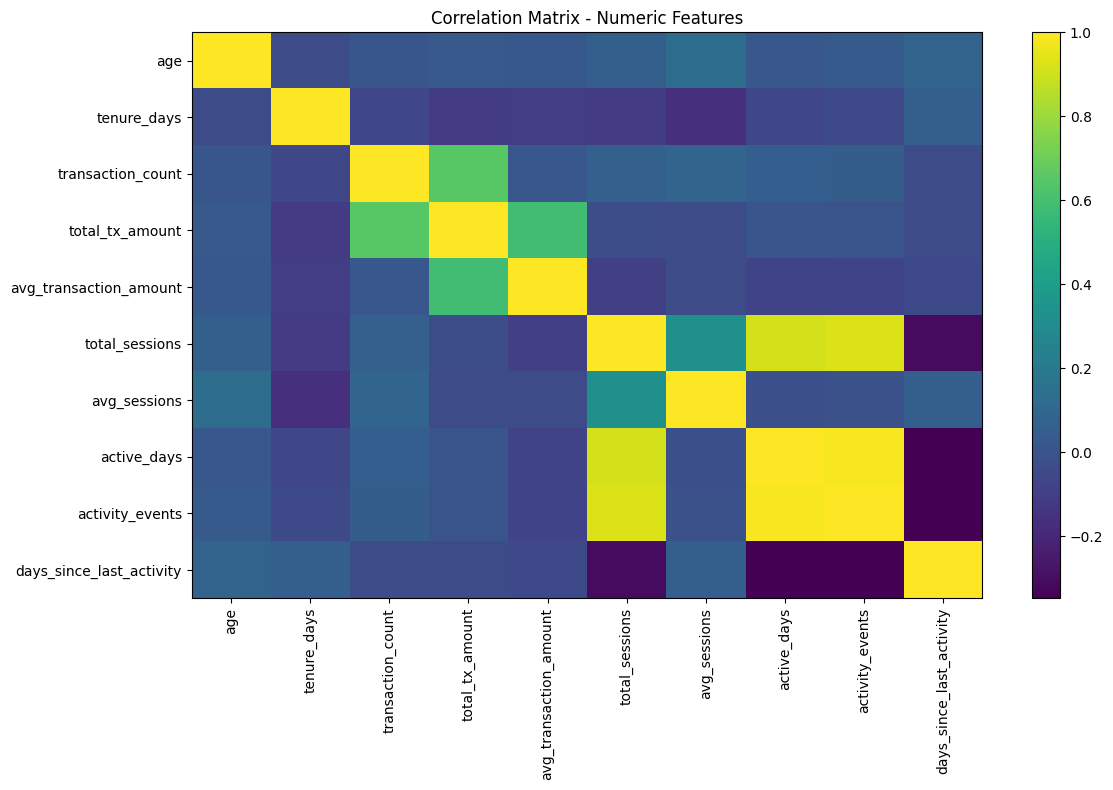

In [ ]:
plt.figure(figsize=(12, 8))

plt.imshow(
    corr_matrix,
    aspect='auto'
)

plt.colorbar()

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title('Correlation Matrix - Numeric Features')

plt.tight_layout()
plt.show()

## **Split Data**

In [ ]:
numeric_features = [
    'age',
    'tenure_days',
    'transaction_count',
    'avg_transaction_amount',
    'total_sessions',
    'days_since_last_activity'
]

categorical_features = [
    'acquisition_channel',
    'city',
    'most_used_feature'
]

target = 'is_churn'

In [ ]:
X = df_model[
    numeric_features +
    categorical_features
].copy()

y = df_model[target].copy()

In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (250, 9)
y shape: (250,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training: (200, 9)
Testing : (50, 9)

Training target distribution:
is_churn
0    141
1     59
Name: count, dtype: int64

Testing target distribution:
is_churn
0    35
1    15
Name: count, dtype: int64


## **Preprocessing**

In [ ]:
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        (
            'onehot',
            OneHotEncoder(
                handle_unknown='ignore',
                drop='first'
            )
        )
    ]
)

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            numeric_transformer,
            numeric_features
        ),
        (
            'cat',
            categorical_transformer,
            categorical_features
        )
    ]
)

## **Logistics Regression**

###**Model Building**

In [ ]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

In [ ]:
logistic_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', logistic_model)
    ]
)

logistic_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'tenure_days',
                                                   'transaction_count',
                                                   'avg_transaction_amount',
                                                   'total_sessions',
                                                   'days_since_last_activity']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['acquisition_channel',
                                                   'city',
                                                   'most_used_feature'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

###**Model Prediction**

In [ ]:
y_pred = logistic_pipeline.predict(X_test)
y_pred

array([1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0,
       0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0,
       0, 1, 0, 1, 1, 0])

In [ ]:
y_prob = logistic_pipeline.predict_proba(X_test)[:, 1]
y_prob

array([0.50867515, 0.49293678, 0.32316782, 0.47481756, 0.36107032,
       0.34559571, 0.35781328, 0.49836205, 0.25406754, 0.35075053,
       0.35368967, 0.55612886, 0.46214874, 0.51752801, 0.49995535,
       0.44211036, 0.59783198, 0.58224084, 0.45676605, 0.67346014,
       0.54556162, 0.41745477, 0.47703742, 0.35491128, 0.33912532,
       0.50305651, 0.60610253, 0.39342763, 0.48033834, 0.27357847,
       0.72207315, 0.54720679, 0.51689443, 0.48111484, 0.50563256,
       0.54375246, 0.39909791, 0.50823899, 0.46263193, 0.35455572,
       0.01194772, 0.43389566, 0.68441162, 0.47208863, 0.13107732,
       0.52059748, 0.43024543, 0.5482216 , 0.51202765, 0.41166108])

###**Model Evaluation**

In [ ]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

pr_auc = average_precision_score(
    y_test,
    y_prob
)

metrics_df = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC-AUC',
        'PR-AUC'
    ],
    'Value': [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        pr_auc
    ]
})

metrics_df

,Metric,Value
0,Accuracy,0.60
1,Precision,0.37
2,Recall,0.47
3,F1-Score,0.41
4,ROC-AUC,0.54
5,PR-AUC,0.34


In [ ]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            'Active',
            'Churn'
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Active       0.74      0.66      0.70        35
       Churn       0.37      0.47      0.41        15

    accuracy                           0.60        50
   macro avg       0.56      0.56      0.55        50
weighted avg       0.63      0.60      0.61        50



In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[23 12]
 [ 8  7]]


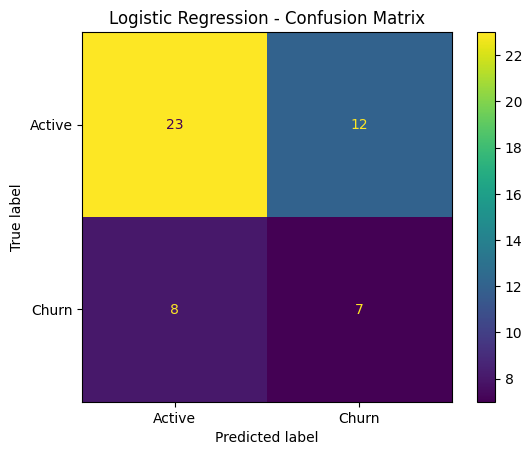

In [ ]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Active', 'Churn']
)

disp.plot()

plt.title('Logistic Regression - Confusion Matrix')
plt.show()

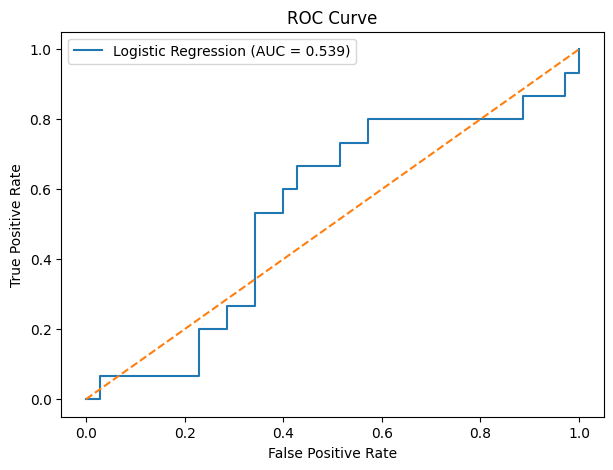

In [ ]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

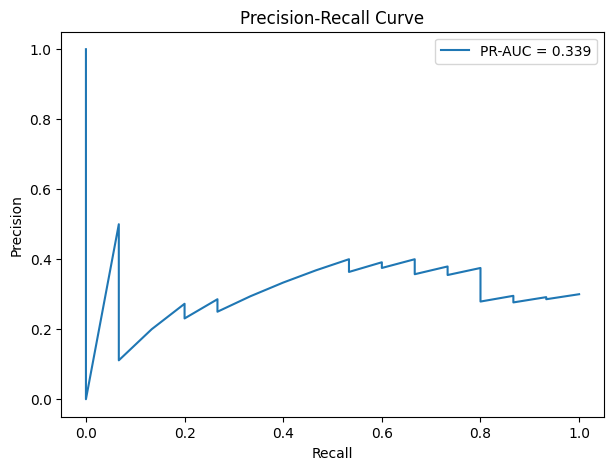

In [ ]:
precision_curve, recall_curve, pr_thresholds = (
    precision_recall_curve(
        y_test,
        y_prob
    )
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall_curve,
    precision_curve,
    label=f'PR-AUC = {pr_auc:.3f}'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

###**Results**

In [ ]:
import statsmodels.api as sm

In [ ]:
# Transform training data menggunakan preprocessor
X_train_processed = (
    logistic_pipeline
    .named_steps['preprocessor']
    .transform(X_train)
)

# Convert sparse matrix jika diperlukan
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

feature_names_sm = (
    logistic_pipeline
    .named_steps['preprocessor']
    .get_feature_names_out()
)

X_train_sm = pd.DataFrame(
    X_train_processed,
    columns=feature_names_sm,
    index=X_train.index
)

# Add intercept
X_train_sm = sm.add_constant(X_train_sm)

# Fit statsmodels logistic regression
logit_sm = sm.Logit(
    y_train,
    X_train_sm
)

result_sm = logit_sm.fit(
    disp=False
)

print(result_sm.summary())

                           Logit Regression Results                           
Dep. Variable:               is_churn   No. Observations:                  200
Model:                          Logit   Df Residuals:                      185
Method:                           MLE   Df Model:                           14
Date:                Wed, 07 Oct 2026   Pseudo R-squ.:                 0.03688
Time:                        07:08:14   Log-Likelihood:                -116.84
converged:                       True   LL-Null:                       -121.31
Covariance Type:            nonrobust   LLR p-value:                    0.8344
                                         coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
const                                 -1.2946      0.516     -2.508      0.012      -2.306      -0.283
num__age                               0.0790      0.166   

In [ ]:
params = result_sm.params
conf = result_sm.conf_int()

odds_ratio = np.exp(params)
conf_odds = np.exp(conf)

p_values = result_sm.pvalues

inference_df = pd.DataFrame({
    'feature': params.index,
    'coefficient': params.values,
    'odds_ratio': odds_ratio.values,
    'p_value': p_values.values,
    'CI_lower': conf_odds[0].values,
    'CI_upper': conf_odds[1].values
})

inference_df['significant_0.05'] = (
    inference_df['p_value'] < 0.05
)

inference_df = inference_df.sort_values(
    'p_value'
)

inference_df

,feature,coefficient,odds_ratio,p_value,CI_lower,CI_upper,significant_0.05
0,const,-1.29,0.27,0.01,0.10,0.75,True
3,num__transaction_count,-0.28,0.75,0.09,0.54,1.05,False
12,cat__most_used_feature_loan_apply,0.51,1.66,0.22,0.74,3.72,False
5,num__total_sessions,0.19,1.20,0.28,0.86,1.69,False
6,num__days_since_last_activity,0.15,1.16,0.38,0.83,1.63,False
4,num__avg_transaction_amount,-0.14,0.87,0.41,0.62,1.22,False
8,cat__acquisition_channel_Organic,0.39,1.48,0.43,0.56,3.87,False
14,cat__most_used_feature_promo_click,0.35,1.42,0.48,0.53,3.76,False
10,cat__city_Jakarta,0.25,1.28,0.52,0.60,2.74,False
1,num__age,0.08,1.08,0.63,0.78,1.50,False


## **Random Forest Classifier**

In [ ]:
final_numeric_features = [
    'age',
    'tenure_days',
    'transaction_count',
    'avg_transaction_amount',
    'total_sessions',
    'days_since_last_activity'
]

final_categorical_features = [
    'acquisition_channel',
    'city',
    'most_used_feature'
]

target = 'is_churn'

In [ ]:
X = df_model[
    final_numeric_features + final_categorical_features
].copy()

y = df_model[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget proportion:")
print(y.value_counts(normalize=True))

X shape: (250, 9)
y shape: (250,)

Target distribution:
is_churn
0    176
1     74
Name: count, dtype: int64

Target proportion:
is_churn
0   0.70
1   0.30
Name: proportion, dtype: float64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts())

print("\nTest target:")
print(y_test.value_counts())

Training set: (200, 9)
Test set: (50, 9)

Training target:
is_churn
0    141
1     59
Name: count, dtype: int64

Test target:
is_churn
0    35
1    15
Name: count, dtype: int64


In [ ]:
numeric_transformer_rf = Pipeline([
    (
        'imputer',
        SimpleImputer(strategy='median')
    )
])

categorical_transformer_rf = Pipeline([
    (
        'imputer',
        SimpleImputer(strategy='most_frequent')
    ),
    (
        'onehot',
        OneHotEncoder(
            handle_unknown='ignore',
            drop='first'
        )
    )
])

preprocessor_rf = ColumnTransformer([
    (
        'num',
        numeric_transformer_rf,
        final_numeric_features
    ),
    (
        'cat',
        categorical_transformer_rf,
        final_categorical_features
    )
])

###**Model Building**

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

In [ ]:
rf_pipeline = Pipeline([
    (
        'preprocessor',
        preprocessor_rf
    ),
    (
        'model',
        rf_model
    )
])

In [ ]:
rf_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['age', 'tenure_days',
                                                   'transaction_count',
                                                   'avg_transaction_amount',
                                                   'total_sessions',
                                                   'days_since_last_activity']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['acquisition_channel',
                                                   'city',
                                                   'most_used_feature'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced', max_depth=5,
                                        min_samples_leaf=5,
                                        min_samples_split=10, n_estimators=300,
                                        n_jobs=-1, random_state=42))])

###**Model Prediction**

In [ ]:
y_pred_rf = rf_pipeline.predict(X_test)
y_pred_rf

array([1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 1, 0, 0])

In [ ]:
y_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]
y_prob_rf

array([0.51924935, 0.31787404, 0.4566429 , 0.41614979, 0.31223293,
       0.4781311 , 0.33625191, 0.40474292, 0.30053479, 0.43010747,
       0.28296372, 0.34067918, 0.35740673, 0.43436539, 0.43115946,
       0.46238741, 0.49728098, 0.32307869, 0.48102683, 0.49303471,
       0.62327088, 0.3707027 , 0.55097835, 0.3205762 , 0.31796656,
       0.4580246 , 0.4247784 , 0.34160368, 0.42297708, 0.22754579,
       0.59833273, 0.38020003, 0.57912275, 0.44607946, 0.3518367 ,
       0.48737   , 0.32147937, 0.41137998, 0.33775824, 0.36325029,
       0.40089854, 0.34248259, 0.70634044, 0.47172172, 0.32046232,
       0.41124857, 0.59623171, 0.50670906, 0.26994812, 0.38831349])

###**Model Evaluation**

In [ ]:
rf_metrics = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC-AUC',
        'PR-AUC'
    ],
    'Value': [
        accuracy_score(
            y_test,
            y_pred_rf
        ),
        precision_score(
            y_test,
            y_pred_rf,
            zero_division=0
        ),
        recall_score(
            y_test,
            y_pred_rf,
            zero_division=0
        ),
        f1_score(
            y_test,
            y_pred_rf,
            zero_division=0
        ),
        roc_auc_score(
            y_test,
            y_prob_rf
        ),
        average_precision_score(
            y_test,
            y_prob_rf
        )
    ]
})

rf_metrics

,Metric,Value
0,Accuracy,0.70
1,Precision,0.50
2,Recall,0.27
3,F1-Score,0.35
4,ROC-AUC,0.67
5,PR-AUC,0.52


In [ ]:
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=[
            'Active',
            'Churn'
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Active       0.74      0.89      0.81        35
       Churn       0.50      0.27      0.35        15

    accuracy                           0.70        50
   macro avg       0.62      0.58      0.58        50
weighted avg       0.67      0.70      0.67        50



In [ ]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

print("Random Forest Confusion Matrix:")
print(cm_rf)

Random Forest Confusion Matrix:
[[31  4]
 [11  4]]


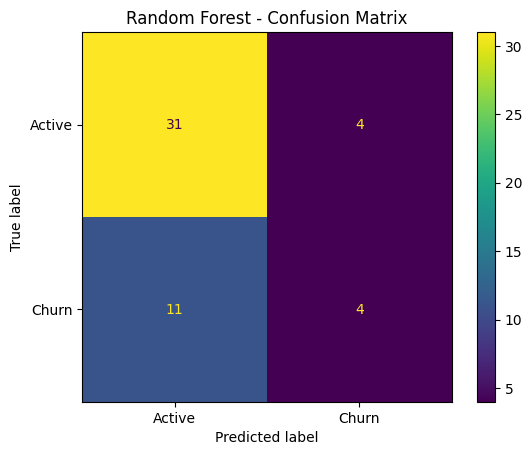

In [ ]:
ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=[
        'Active',
        'Churn'
    ]
).plot()

plt.title(
    'Random Forest - Confusion Matrix'
)

plt.show()

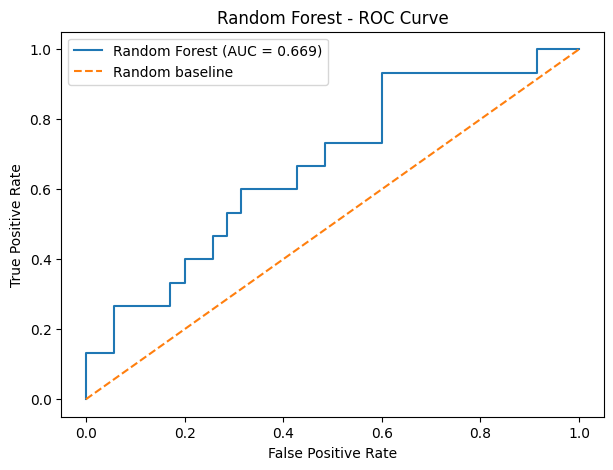

In [ ]:
fpr_rf, tpr_rf, thresholds_rf = roc_curve(
    y_test,
    y_prob_rf
)

roc_auc_rf = roc_auc_score(
    y_test,
    y_prob_rf
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f'Random Forest (AUC = {roc_auc_rf:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random baseline'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest - ROC Curve')
plt.legend()

plt.show()

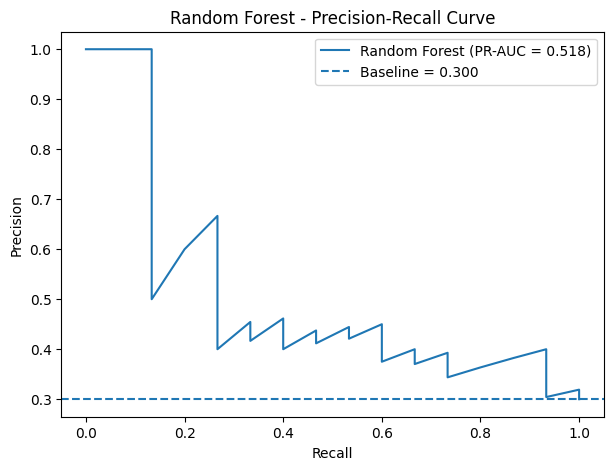

In [ ]:
precision_rf, recall_rf, thresholds_pr_rf = (
    precision_recall_curve(
        y_test,
        y_prob_rf
    )
)

pr_auc_rf = average_precision_score(
    y_test,
    y_prob_rf
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall_rf,
    precision_rf,
    label=f'Random Forest (PR-AUC = {pr_auc_rf:.3f})'
)

baseline_pr = y_test.mean()

plt.axhline(
    baseline_pr,
    linestyle='--',
    label=f'Baseline = {baseline_pr:.3f}'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Random Forest - Precision-Recall Curve')
plt.legend()

plt.show()

###**Feature Importance**

In [ ]:
feature_names_rf = (
    rf_pipeline
    .named_steps['preprocessor']
    .get_feature_names_out()
)

importances_rf = (
    rf_pipeline
    .named_steps['model']
    .feature_importances_
)

feature_importance_rf = pd.DataFrame({
    'feature': feature_names_rf,
    'importance': importances_rf
})

feature_importance_rf = (
    feature_importance_rf
    .sort_values(
        'importance',
        ascending=False
    )
    .reset_index(drop=True)
)

feature_importance_rf

,feature,importance
0,num__transaction_count,0.19
1,num__avg_transaction_amount,0.15
2,num__tenure_days,0.15
3,num__total_sessions,0.15
4,num__days_since_last_activity,0.11
5,num__age,0.10
6,cat__most_used_feature_loan_apply,0.03
7,cat__city_Surabaya,0.02
8,cat__city_Jakarta,0.02
9,cat__acquisition_channel_Organic,0.02


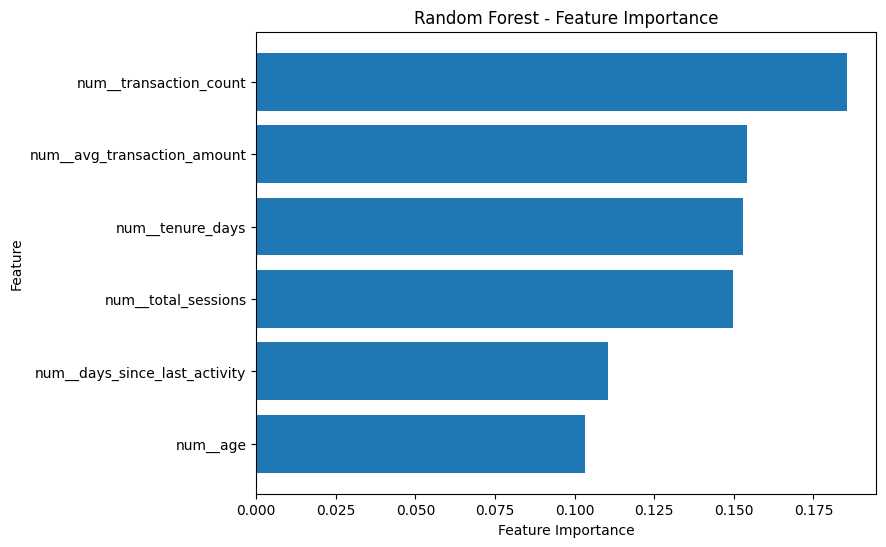

In [ ]:
top_n = 6

plot_df = (
    feature_importance_rf
    .head(top_n)
    .sort_values(
        'importance',
        ascending=True
    )
)

plt.figure(figsize=(8, 6))

plt.barh(
    plot_df['feature'],
    plot_df['importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title(
    'Random Forest - Feature Importance'
)

plt.show()

# **EVALUATION**

##**Model Comparison**

###**Metrics**

In [ ]:
# Table Comparison logistics vs random forest
comparison_table = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC-AUC',
        'PR-AUC'
    ],
    'Logistic Regression': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob),
        average_precision_score(y_test, y_prob)
    ],
    'Random Forest': [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0),
        roc_auc_score(y_test, y_prob_rf),
        average_precision_score(y_test, y_prob_rf)
    ]
})

comparison_table

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.60,0.70
1,Precision,0.37,0.50
2,Recall,0.47,0.27
3,F1-Score,0.41,0.35
4,ROC-AUC,0.54,0.67
5,PR-AUC,0.34,0.52


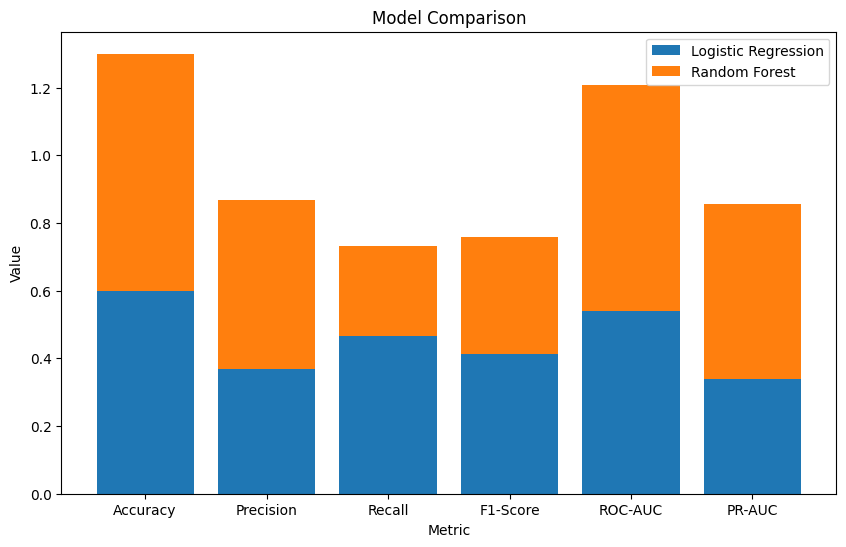

In [ ]:
# Plot
plt.figure(figsize=(10, 6))

plt.bar(
    comparison_table['Metric'],
    comparison_table['Logistic Regression'],
    label='Logistic Regression')

plt.bar(
    comparison_table['Metric'],
    comparison_table['Random Forest'],
    bottom=comparison_table['Logistic Regression'],
    label='Random Forest')

plt.xlabel('Metric')
plt.ylabel('Value')
plt.title('Model Comparison')
plt.legend()

plt.show()

###**Cross Validation**

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

In [ ]:
cv_logistic = cross_validate(
    logistic_pipeline,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

logistic_cv_results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC-AUC',
        'PR-AUC'
    ],
    'Mean': [
        cv_logistic['test_accuracy'].mean(),
        cv_logistic['test_precision'].mean(),
        cv_logistic['test_recall'].mean(),
        cv_logistic['test_f1'].mean(),
        cv_logistic['test_roc_auc'].mean(),
        cv_logistic['test_pr_auc'].mean()
    ],
    'Std': [
        cv_logistic['test_accuracy'].std(),
        cv_logistic['test_precision'].std(),
        cv_logistic['test_recall'].std(),
        cv_logistic['test_f1'].std(),
        cv_logistic['test_roc_auc'].std(),
        cv_logistic['test_pr_auc'].std()
    ]
})

logistic_cv_results

,Metric,Mean,Std
0,Accuracy,0.50,0.03
1,Precision,0.28,0.06
2,Recall,0.46,0.15
3,F1-Score,0.35,0.09
4,ROC-AUC,0.49,0.06
5,PR-AUC,0.30,0.03


In [ ]:
cv_rf = cross_validate(
    rf_pipeline,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

rf_cv_results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC-AUC',
        'PR-AUC'
    ],
    'Mean': [
        cv_rf['test_accuracy'].mean(),
        cv_rf['test_precision'].mean(),
        cv_rf['test_recall'].mean(),
        cv_rf['test_f1'].mean(),
        cv_rf['test_roc_auc'].mean(),
        cv_rf['test_pr_auc'].mean()
    ],
    'Std': [
        cv_rf['test_accuracy'].std(),
        cv_rf['test_precision'].std(),
        cv_rf['test_recall'].std(),
        cv_rf['test_f1'].std(),
        cv_rf['test_roc_auc'].std(),
        cv_rf['test_pr_auc'].std()
    ]
})

rf_cv_results

,Metric,Mean,Std
0,Accuracy,0.68,0.06
1,Precision,0.45,0.13
2,Recall,0.35,0.14
3,F1-Score,0.39,0.13
4,ROC-AUC,0.58,0.06
5,PR-AUC,0.48,0.08


In [ ]:
cv_comparison = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC-AUC',
        'PR-AUC'
    ],
    'Logistic Regression Mean': logistic_cv_results['Mean'],
    'Logistic Regression Std': logistic_cv_results['Std'],
    'Random Forest Mean': rf_cv_results['Mean'],
    'Random Forest Std': rf_cv_results['Std']
})

cv_comparison

,Metric,Logistic Regression Mean,Logistic Regression Std,Random Forest Mean,Random Forest Std
0,Accuracy,0.50,0.03,0.68,0.06
1,Precision,0.28,0.06,0.45,0.13
2,Recall,0.46,0.15,0.35,0.14
3,F1-Score,0.35,0.09,0.39,0.13
4,ROC-AUC,0.49,0.06,0.58,0.06
5,PR-AUC,0.30,0.03,0.48,0.08


# **PREDICTION**

## **Final Model**

In [ ]:
# ============================================================
# FINAL FEATURES
# ============================================================

final_numeric_features = [
    'age',
    'tenure_days',
    'transaction_count',
    'avg_transaction_amount',
    'total_sessions',
    'days_since_last_activity'
]

final_categorical_features = [
    'acquisition_channel',
    'city',
    'most_used_feature'
]

final_features = (
    final_numeric_features +
    final_categorical_features
)

target = 'is_churn'

In [ ]:
X = df_model[final_features].copy()
y = df_model[target].copy()

print("X shape :", X.shape)
print("y shape :", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget proportion:")
print(y.value_counts(normalize=True))

X shape : (250, 9)
y shape : (250,)

Target distribution:
is_churn
0    176
1     74
Name: count, dtype: int64

Target proportion:
is_churn
0   0.70
1   0.30
Name: proportion, dtype: float64


In [ ]:
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median'))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(
            handle_unknown='ignore',
            drop='first'
        ))
    ]
)

preprocessor_rf = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, final_numeric_features),
        ('cat', categorical_transformer, final_categorical_features)
    ]
)

In [ ]:
rf_model_final = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

In [ ]:
rf_model_final

RandomForestClassifier(class_weight='balanced', max_depth=5, min_samples_leaf=5,
                       min_samples_split=10, n_estimators=300, n_jobs=-1,
                       random_state=42)

In [ ]:
rf_pipeline_final = Pipeline(
    steps=[
        ('preprocessor', preprocessor_rf),
        ('model', rf_model)
    ]
)

rf_pipeline_final.fit(X, y)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['age', 'tenure_days',
                                                   'transaction_count',
                                                   'avg_transaction_amount',
                                                   'total_sessions',
                                                   'days_since_last_activity']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['acquisition_channel',
                                                   'city',
                                                   'most_used_feature'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced', max_depth=5,
                                        min_samples_leaf=5,
                                        min_samples_split=10, n_estimators=300,
                                        n_jobs=-1, random_state=42))])

In [ ]:
df_prediction = df_model[
    ['user_id', 'is_churn']
].copy()

df_prediction['churn_probability'] = (
    rf_pipeline_final.predict_proba(X)[:, 1]
)

In [ ]:
df_prediction

,user_id,is_churn,churn_probability
0,1,0,0.23
1,2,0,0.27
2,3,0,0.30
3,4,0,0.48
4,5,0,0.29
...,...,...,...
245,246,0,0.36
246,247,1,0.76
247,248,0,0.29
248,249,0,0.56


In [ ]:
df_prediction = df_prediction.sort_values(
    'churn_probability',
    ascending=False
).reset_index(drop=True)

df_prediction['risk_rank'] = (
    df_prediction.index + 1
)

df_prediction

,user_id,is_churn,churn_probability,risk_rank
0,145,1,0.81,1
1,148,1,0.79,2
2,43,1,0.78,3
3,129,1,0.78,4
4,45,1,0.77,5
...,...,...,...,...
245,219,0,0.23,246
246,1,0,0.23,247
247,216,0,0.22,248
248,189,0,0.22,249


In [ ]:
risk_profile = df_model[
    [
        'user_id',
        'is_churn',
        'age',
        'acquisition_channel',
        'city',
        'transaction_count',
        'avg_transaction_amount',
        'total_sessions',
        'days_since_last_activity',
        'tenure_days',
        'most_used_feature'
    ]
].merge(
    df_prediction[
        [
            'user_id',
            'churn_probability',
            'risk_rank'
        ]
    ],
    on='user_id',
    how='left'
)

risk_profile = risk_profile.sort_values(
    'churn_probability',
    ascending=False
)

risk_profile

,user_id,is_churn,age,acquisition_channel,city,transaction_count,avg_transaction_amount,total_sessions,days_since_last_activity,tenure_days,most_used_feature,churn_probability,risk_rank
144,145,1,49.00,Affiliate,Jakarta,1.00,1422014.00,36,14,311,promo_click,0.81,1
147,148,1,44.00,Referral,Bandung,0.00,0.00,26,9,308,browse,0.79,2
42,43,1,36.00,Ads,Jakarta,1.00,871279.00,24,10,413,browse,0.78,3
128,129,1,23.00,Affiliate,Jakarta,0.00,0.00,16,15,327,promo_click,0.78,4
44,45,1,23.00,Affiliate,Jakarta,1.00,2076230.00,26,16,411,promo_click,0.77,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
218,219,0,25.00,Affiliate,Surabaya,3.00,4694054.33,13,16,237,browse,0.23,246
0,1,0,33.00,Referral,Jakarta,5.00,4529720.60,11,5,455,payment,0.23,247
215,216,0,50.00,Organic,Bandung,5.00,3012806.60,46,2,240,browse,0.22,248
188,189,0,21.00,Referral,Jakarta,4.00,2393288.50,11,19,267,payment,0.22,249


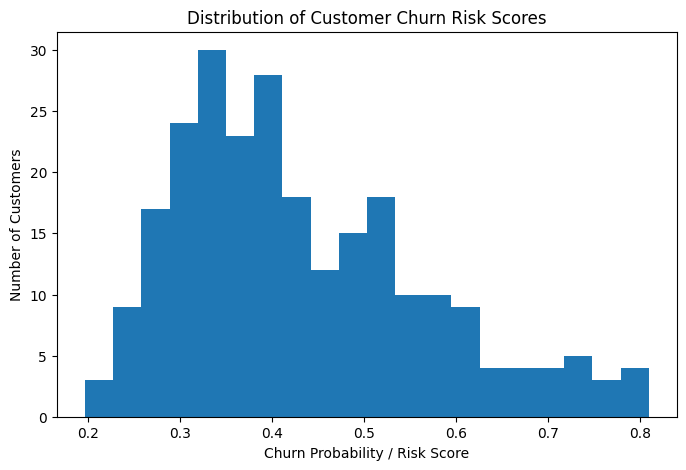

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_prediction['churn_probability'],
    bins=20
)

plt.xlabel('Churn Probability / Risk Score')
plt.ylabel('Number of Customers')
plt.title('Distribution of Customer Churn Risk Scores')

plt.show()

In [ ]:
risk_summary = (
    risk_profile
    .groupby('is_churn')['churn_probability']
    .agg(
        count='count',
        mean='mean',
        median='median',
        min='min',
        max='max'
    )
)

risk_summary

,count,mean,median,min,max
is_churn,,,,,
0,176,0.37,0.35,0.20,0.61
1,74,0.58,0.56,0.39,0.81


In [ ]:
feature_names = (
    rf_pipeline_final
    .named_steps['preprocessor']
    .get_feature_names_out()
)

feature_importance = (
    rf_pipeline_final
    .named_steps['model']
    .feature_importances_
)

importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': feature_importance
})

importance_df = importance_df.sort_values(
    'importance',
    ascending=False
).reset_index(drop=True)

importance_df

,feature,importance
0,num__transaction_count,0.22
1,num__tenure_days,0.15
2,num__avg_transaction_amount,0.14
3,num__total_sessions,0.13
4,num__days_since_last_activity,0.11
5,num__age,0.10
6,cat__most_used_feature_loan_apply,0.03
7,cat__city_Surabaya,0.02
8,cat__acquisition_channel_Organic,0.02
9,cat__most_used_feature_payment,0.02


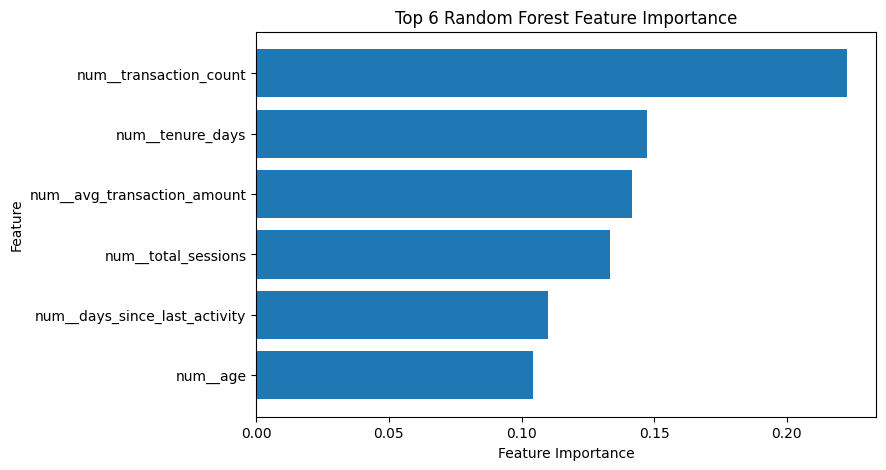

In [ ]:
top_features = importance_df.head(6).sort_values(
    'importance'
)

plt.figure(figsize=(8, 5))

plt.barh(
    top_features['feature'],
    top_features['importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 6 Random Forest Feature Importance')

plt.show()